This notebook contains the code which is to be used to acgieve path planning with traffic prediction.

Task -1 LayoutReader.py
Functionality
1. read .csv as numpy array
2. find all {obs, ava, shelf, dock}
3. define zones
3. define zonesDict[loc]=zone



New warehouse layout

Mounting the sahred drive to access the .csv file which has the layout of the map

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
from google.colab import drive
drive.mount("/content/gdrive")

Mounted at /content/gdrive


In [5]:
%cd 
# !ls "/content/gdrive/Shared Drives/Winter Simulation 2021"
!ls "/content/gdrive/Shareddrives/Winter Simulation 2021"
!ls 

/root
 array1.csv
 array2.csv
 array3_6_26_1.csv
 array3.csv
 array4_6_26_1.csv
 array4.csv
 array_dis_no_traffic_avoidance_6_27_1.csv
 array_dis_traffic_avoidance_6_27_1.csv
 array_no_traffic_avoidance_6_27_1.csv
 array_no_traffic_avoidance_7_6_21.csv
 array_no_traffic_num_vehicles_avoided_6_27_1.csv
 array_no_traffic_num_vehicles_avoided_7_6_21.csv
 array_no_traffic_vehicles_avoided_6_26_1.csv
 array_no_traffic_vehicles_avoided.csv
 array_t_no_traffic_6_26_1.csv
 array_t_no_traffic_6_27_1.csv
 array_t_no_traffic_7_6_21.csv
 array_t_no_traffic.csv
 array_traffic_avoidance_6_27_1.csv
 array_traffic_avoidance_7_6_21.csv
 array_traffic_num_vehicles_avoided_6_27_1.csv
 array_traffic_num_vehicles_avoided_7_6_21.csv
 array_traffic_vehicles_avoided_6_26_1.csv
 array_traffic_vehicles_avoided.csv
 array_t_traffic_avoid_6_26_1.csv
 array_t_traffic_avoid_6_27_1.csv
 array_t_traffic_avoid_7_6_21.csv
 array_t_traffic_avoid.csv
 BusinessMeasurement.gsheet
'Copy_of_training_in_pieces_(1).ipynb'
 CPw

1.

bold text

In [6]:
import numpy as np
filein = "/content/gdrive/Shareddrives/Winter Simulation 2021/Layout_updated_2021 (1).csv"
data = np.loadtxt(open(filein, "rb"), delimiter=",")
data


array([[ -1.,  -1.,  -1., ...,  -1.,  -1.,  -1.],
       [ -1.,  50.,   0., ...,   0.,  50.,  -1.],
       [ -1.,   0., 200., ..., 100.,   0.,  -1.],
       ...,
       [ -1.,   0., 200., ..., 100.,   0.,  -1.],
       [ -1.,  50.,   0., ...,   0.,  50.,  -1.],
       [ -1.,  -1.,  -1., ...,  -1.,  -1.,  -1.]])

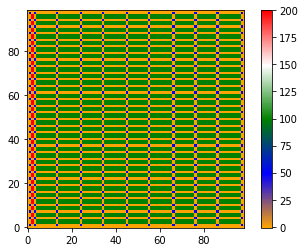

In [ ]:
from matplotlib import pyplot
import matplotlib as mpl

fig = pyplot.figure(2)

cmap2 = mpl.colors.LinearSegmentedColormap.from_list('my_colormap',
                                           ['orange','blue','green','white','red'],
                                           256)

img2 = pyplot.imshow(data,interpolation='nearest',
                    cmap = cmap2,
                    origin='lower')

pyplot.colorbar(img2,cmap=cmap2)

fig.savefig("/content/gdrive/Shareddrives/Winter Simulation 2021/Warehouse_layout.png")

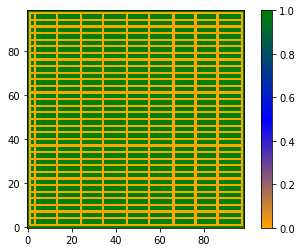

In [ ]:
maze1=np.array(data)
maze1 = np.where(maze1 == 100, 1, maze1)
maze1 = np.where(maze1 == -1, 1, maze1)
maze1 = np.where(maze1 == 200, 1, maze1)
maze1 = np.where(maze1 == 50, 0, maze1)
              



fig = pyplot.figure(2)

cmap2 = mpl.colors.LinearSegmentedColormap.from_list('my_colormap',
                                           ['orange','blue','green'],
                                           256)

img2 = pyplot.imshow(maze1,interpolation='nearest',
                    cmap = cmap2,
                    origin='lower')

pyplot.colorbar(img2,cmap=cmap2)

fig.savefig("/content/gdrive/Shareddrives/Winter Simulation 2021/Warehouse_maze_seen_by_ASTAR.png")


define zones \\
define zonesDict[loc]=zone \\
A zone is between 2 junctions

In [7]:
size_data=np.size(data)
shape_data=np.shape(data)
'''print(size_data)
print(shape_data)
print(data.shape)'''

def countX(lst, x):
    count = 0
    for el in lst:
      for ele in el:
        if (ele == x):
            count = count + 1
    return count

print('{} has occurred {} times'.format(50, countX(data, 50)))
print('{} has occurred {} times'.format(100, countX(data, 100)))
print('{} has occurred {} times'.format(200, countX(data, 200)))
print('{} has occurred {} times'.format(0, countX(data, 0)))
print('{} has occurred {} times'.format(-1, countX(data, -1)))

zones_dictionary={}
zone_number_of_cells_dict=[]

#New zoning 
#Involves labeling available free paths as zones 
#It can be noticed that there are vertical and horizontal free paths which make up the zones
#If a zone is enterd, it can be left only through the intersections 
zone = 0
zone1 = 1
zone2=1 
c50=0
c0=0
maze=np.array(data)
else_counter=0
for row in range (0,shape_data[0]-1) :
    for colm in range(0,shape_data[1]-1):
        if maze[row,colm]==50:
             else_counter=0
             zone=zone+1
             #zone1=zone1+1
             zones_dictionary[(row,colm)] = zone
             zone=zone+1
             c50=c50+1
        elif maze[row,colm]==0 and maze[row,colm+1]!=200 and maze[row,colm+1]!=100 and maze[row,colm+1]!=-1:
            #print(row,colm)
            zones_dictionary[(row,colm)] = zone
            c0=c0+1
        else:
          else_counter=else_counter+1
          if else_counter==22:
             zone=zone-1

            #zones_dictionary[(row,colm)]=0
          
            
for colm in range (0,shape_data[1]-1) :
    for row in range(0,shape_data[0]-1):
        if maze[row,colm]==50:
             if else_counter>=33:
                zone=zone-1

             else_counter=0
             zone=zone+1         
             c50=c50+1
        elif maze[row,colm]==0 and maze[row+1,colm]!=200 and maze[row+1,colm]!=100 and maze[row+1,colm]!=-1 :
                  #print(row,colm)
                  zones_dictionary[(row,colm)] = zone

                  
                  #print(row,colm)
                  #print(row,colm)
                  c0=c0+1
        else:
          #continue
          else_counter=else_counter+1
          #33

#print(zones_dictionary)
#zones_dictionary = {key:val for key, val in zones_dictionary.items() if val != 0}
#print(zones_dictionary)
counter =0
for i in zones_dictionary:
    #print(i)
    if zones_dictionary[i]==3:
        print(i)
        counter=counter+1
print(counter)
#Should be 1238 
#print(0)
#print(c0)
#print(50)
#print(c50)
#print(c+co)
print(zone)
print(zone_number_of_cells_dict)

50 has occurred 363 times
100 has occurred 5440 times
200 has occurred 64 times
0 has occurred 3542 times
-1 has occurred 392 times
(1, 4)
(1, 5)
(1, 6)
(1, 7)
(1, 8)
(1, 9)
(1, 10)
(1, 11)
(1, 12)
9
1045
[]


In [8]:
zone_number_of_cells_dict=[]

from collections import Counter
for numb in range(0,zone):
  Counter_num_cell = Counter(zones_dictionary.values())[numb]
  zone_number_of_cells_dict.append(Counter_num_cell)
  #print(Counter_num_cell)
# 3

In [9]:
print(zone_number_of_cells_dict)
print(zone)
print(len(zone_number_of_cells_dict))

[1, 1, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 9, 1, 10, 1, 1, 1, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 9, 1, 10, 1, 1, 1, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 9, 1, 10, 1, 1, 1, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 9, 1, 10, 1, 1, 1, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 9, 1, 10, 1, 1, 1, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 9, 1, 10, 1, 1, 1, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 9, 1, 10, 1, 1, 1, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 9, 1, 10, 1, 1, 1, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 9, 1, 10, 1, 1, 1, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 9, 1, 10, 1, 1, 1, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 9, 1, 10, 1, 1, 1, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 9, 1, 10, 1, 1, 1, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 9, 1, 10, 1, 1, 1, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 9, 1, 10, 1, 1, 1, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 9, 1, 1

In [10]:
counter=[0]*zone
for j in range(0,zone):
  for i in zones_dictionary:
    #print(i)
    if zones_dictionary[i]==j:
        counter[j]=counter[j]+1

In [11]:
print(sum(counter))

3905


1. randomly pick {init, shelf, dock}
2. compute shortest path with A *

This part of code is to check if the points are being accessed correctly i.e, the initial positions are random free spaces, then the agent goes to the rack and subsequently to the dock

In [13]:
from numpy import array, where
from random import choice


This part of the code is to convert the map to occupancy grids.
I have assumed that the docks are obstacles when going to the rack but free space during docking. \\
Doubt-
Is it alright to consider that the agents can drive through docks?

A* assumes that it knows the entire environment while making its decisions i.e., it knows the location of all the obstacles.
In a warehouse with multipleagents working together in a decentralized manner, this is not true. Then, when the vehicles use A* the map has to be updated often to reflect the change in the location of other agents. Updating the map at every step would be like having a centralized system. Not updating the map would mean, the agent fails to avoid other agents. This brings in the question of how to simulate the decentralized A* multi agents. 
If the agents know the floor plan of the warehouse/ have the map but do not know the location of other robots and plans its path without taking them into consideration, uses its collision avoidance algorithm to prevent running into each other i.e. the agents wait when there is another agent in the way and continues whenit gets free way - the traffic can be predicted. 

The following code does that.

Instead of just considering the path, if we consider the step number, it will help with the prediction of points where more than 1 agent wants to be at the same time as another . So we can track the congestion as well as well-points that needs sharing 

This is the A* with graphics that helps with debugging. 

The following snippet is to test the path planner.

It can be observed from the above results that the maze expects teh input as (column, row) and not the other way round.
This was further tested and proved by the below code. 

Now that we have planned for 1 agent, lets plan for more than 1 and see the traffic 

1. test path of active agents
2. measure zones business

In [14]:
import random

In [15]:
#!/usr/bin/python
class PathPlanner:

    def __init__(self, grid, visual=False):
        """
        Constructor of the PathPlanner Class.
        :param grid: List of lists that represents the
        occupancy map/grid. List should only contain 0's
        for open nodes and 1's for obstacles/walls.
        :param visual: Boolean to determine if Matplotlib
        animation plays while path is found.
        """
        self.grid = grid
        self.visual = True
        self.heuristic = None
        self.goal_node = None

    def calc_heuristic(self):
        """
        Function will create a list of lists the same size
        of the occupancy map, then calculate the cost from the
        goal node to every other node on the map and update the
        class member variable self.heuristic.
        :return: None.
        """
        row = len(self.grid)
        col = len(self.grid[0])

        self.heuristic = [[0 for x in range(col)] for y in range(row)]
        for i in range(row):
            for j in range(col):
                row_diff = abs(i - self.goal_node[0])
                col_diff = abs(j - self.goal_node[1])
                self.heuristic[i][j] = int(abs(row_diff - col_diff) + min(row_diff, col_diff) * 2)

        #print ("Heuristic:")
        #for i in range(len(self.heuristic)):
            #print (self.heuristic[i])

    def a_star(self, start_cart, goal_cart):
        """
        A* Planner method. Finds a plan from a starting node
        to a goal node if one exits.
        :param init: Initial node in an Occupancy map. [x, y].
        Type: List of Ints.
        :param goal: Goal node in an Occupancy map. [x, y].
        Type: List of Ints.
        :return: Found path or -1 if it fails.
        """
        goal = [goal_cart[1], goal_cart[0]]
        self.goal_node = goal
        init = [start_cart[1], start_cart[0]]
        # Calculate the Heuristic for the map
        self.calc_heuristic()

        #print (init, goal)


        # Different move/search direction options:

        delta = [[-1, 0],  # go up
                 [0, -1],  # go left
                 [1, 0],  # go down
                 [0, 1]]  # go right
        delta_name = ['^ ', '< ', 'v ', '> ']


        # Heavily used from some of the A* Examples by Sebastian Thrun:

        closed = [[0 for col in range(len(self.grid[0]))] for row in range(len(self.grid))]
        shortest_path = [['  ' for _ in range(len(self.grid[0]))] for _ in range(len(self.grid))]
        closed[init[0]][init[1]] = 1

        expand = [[-1 for col in range(len(self.grid[0]))] for row in range(len(self.grid))]
        delta_tracker = [[-1 for _ in range(len(self.grid[0]))] for _ in range(len(self.grid))]

        cost = 1
        x = init[0]
        y = init[1]
        g = 0
        f = g + self.heuristic[x][y]
        open = [[f, g, x, y]]

        found = False  # flag that is set when search is complete
        resign = False  # flag set if we can't find expand
        count = 0
        while not found and not resign:
            if len(open) == 0:
                resign = True
                return -1
            else:
                open.sort()
                open.reverse()
                next = open.pop()
                x = next[2]
                y = next[3]
                g = next[1]
                expand[x][y] = count
                count += 1

                if x == goal[0] and y == goal[1]:
                    found = True
                else:
                    for i in range(len(delta)):
                        x2 = x + delta[i][0]
                        y2 = y + delta[i][1]
                        if len(self.grid) > x2 >= 0 <= y2 < len(self.grid[0]):
                            if closed[x2][y2] == 0 and self.grid[x2][y2] == 0:
                                g2 = g + cost
                                f = g2 + self.heuristic[x2][y2]
                                open.append([f, g2, x2, y2])
                                closed[x2][y2] = 1
                                delta_tracker[x2][y2] = i

        current_x = goal[0]
        current_y = goal[1]
        shortest_path[current_x][current_y] = '* '
        full_path = []
        while current_x != init[0] or current_y != init[1]:
            previous_x = current_x - delta[delta_tracker[current_x][current_y]][0]
            previous_y = current_y - delta[delta_tracker[current_x][current_y]][1]
            shortest_path[previous_x][previous_y] = delta_name[delta_tracker[current_x][current_y]]
            full_path.append((current_x, current_y))
            current_x = previous_x
            current_y = previous_y
        full_path.reverse()
        #print ("Found the goal in {} iterations.".format(count))
        #print ("full_path: ", full_path[:])


        return full_path[:]

The A* seen above is the same as the earlier A* without the graphics to make it faster at computation. 
Display results in the occupancy grid makes the entire runtime longer


In [45]:
random.seed(30)

In [16]:
#Number of agents = 4,6,8,10
#A zone can be classified as busy / not busy or on a scale of business 
#Which method we pick will decide if we need classification or regression
# Classification seems like a good option 
#This is to measure business
import numpy
from numpy import array, where
from random import choice
def Decentralized_multi_agent_paths (n,k=None,maze_passed=None) :#Added K for consistency with the random generator. Like seeding 
          #n=4
          A=[]

          for i in range (1,n+1):
              if maze_passed==None:
                        maze1=np.array(data)
                        maze1 = np.where(maze1 == 100, 1, maze1)
                        maze1 = np.where(maze1 == -1, 1, maze1)
                        maze1 = np.where(maze1 == 200, 1, maze1)
                        maze1 = np.where(maze1 == 50, 0, maze1)
              if maze_passed !=None:
                maze1=maze_passed

              init_position=random.choice(array(where(data == 0)).T)
              shelf_to_go = random.choice(array(where(data == 100)).T)
              Final_dock=random.choice(array(where(data == 200)).T)

              if data[shelf_to_go[0]-1, shelf_to_go[1]]==0:
                shelf_to_go[0]=shelf_to_go[0] - 1
              else:
                shelf_to_go[0]=shelf_to_go[0] + 1
              end1 = tuple(shelf_to_go) 
              start2 = end1
              if data[Final_dock[0]-1, Final_dock[1]]==0:
                Final_dock[0]=Final_dock[0] - 1
              else:
                Final_dock[0]=Final_dock[0] + 1  

              
              I=tuple(init_position)
              temp = init_position[0]
              init_position[0]=init_position[1]
              init_position[1]=temp

              S=tuple(shelf_to_go)
              temp =shelf_to_go[0]
              shelf_to_go[0]=shelf_to_go[1]
              shelf_to_go[1]=temp

              F=tuple(Final_dock)
              temp=Final_dock[0]
              Final_dock[0]=Final_dock[1]
              Final_dock[1]=temp
  
              start1 = tuple(init_position)
              end1 =tuple(shelf_to_go)
              start2=tuple(shelf_to_go)
              end2 = tuple(Final_dock) 
     
              test_planner = PathPlanner(maze1, True) 
              a1= test_planner.a_star(start1, end1) 
              a2= test_planner.a_star(start2, end2)  
              #print(a1)

              a1=list(a1)
              a1.insert(0,I)
              #for i in range(1,20): #Picking up from the shelf takes 20 time stamps
              #a1.insert(len(a1),S)

              a2=list(a2)
              #for i in range(1,20): #Docking takes 20 time stamps
              a1.insert(0,S)
              #a2.insert(len(a2),F)
              #a1.extend(a2)
              A.append(a1) 
              A.append(a2) 
                       
          return A

In [17]:
# Measuring zone business 
#Number of agents in a zone 
#Number of agents in a zone at a time 
#Number of agents that want to cross a zone at a time
def Zone_business (A1):
      #print(zone)
      No_of_agents_in_Zone=[0] * (zone+1)
      for A in A1:
          #print(A)
          for a in A:
              a=list(a)
              temp_a=list(a)
              #print(temp_a)
              #temp=temp_a[0]
              #temp_a[0]=temp_a[1]
              #temp_a[1]=temp
              #print(temp_a)
              #temp_a[0]=temp_a[0]
              #temp_a[1]=temp_a[1]
              temp_a=tuple(temp_a)
              #temp_a=temp_a
              #print(temp_a)
              val=zones_dictionary.get(temp_a)
              #val=zones_dictionary.get(a)
              #print(val)
              No_of_agents_in_Zone[val]=No_of_agents_in_Zone[val]+1



      #print(No_of_agents_in_Zone)
      return No_of_agents_in_Zone                         

Testing the function for Zone business

The following function defines zone business as a function of time

This part of the code is for generating data to train neural network
This consists of  a function that repeatedly calls the function that plans the path as well as the function that measures the business in a zone
Arbitararily select the total number of vehicles. \\
Is it possible to have varying input to a neural network ?
AN approach I was thinking of is having input as - \\
====>Start location of other vehicles - belonging to which zone & how many

=======>End location of other vehicles - belonging to which zone \\
Suppose there are 14 zones- 
i/p will be \\
start - 1 2 2 1 0 0 0 0 0 0 0 0 0 0 \\
end   - 0 2 0 0 0 1 1 0 0 0 2 0 2 0 \\
Output will be \\
Traffic-1 2 2 1 1 1 1 0 1 1 2 3 2 0 

In [18]:
pip install tqdm

Generating 150000 data points

Basically I need the data to be in a 3d array form 
where the one dimension is the sample number 
one dimension is the i/p-o/p type
and the 3rd dimension is equal to number of zones 
Now we can use this for training 

Incorporating traffic prediction back into path planning 

Step-1 
Calculating time taken to travel in the warehouse -
assuming we know the start and end locations of all the other vehicles that are running in the warehouse.
The number of vehicles can vary between 15-20 

Trying with 5 vehicles that have a particular zone path .


In [ ]:
  #Number of vehicles =10 
  
  from tqdm import tqdm
  from google.colab import files
  import random
  import pandas as pd
  import csv 
  import json
  #def data_generator_for_nn(data_points):
  data_points=5
  ip_1=[]
  ip_2=[]
  ip_3=[]
  op_1=[]
  for N in tqdm(range (0,data_points)): 
    #print(n)
    #n = random. randint(10,15) #randomly generated number between 2 to 20 
    n=1
    A1_n1=Decentralized_multi_agent_paths(n)
    #writing number of vehicles begning their trip in each zone
    for A1 in A1_n1:
      A1_n=[A1]
      Zone_start_trip=[0]*(zone+1)
      Zone_finish_trip=[0]*(zone+1)
      #Zone_rack=[0]*(zone+1)
      for a in A1_n:
        #print(a)
        #print(a[0])
        temp_init=list(a[0])
        #temp=temp_init[0]
        #temp_init[0]=temp_init[1]
        #temp_init[1]=temp
        temp_init=tuple(temp_init)
        init=zones_dictionary.get(temp_init)
        #print(init)
        #print(data[init])
        Zone_start_trip[init]=Zone_start_trip[init]+1

      #writing number of vehicles ending their trip in each zone
      for A1 in A1_n:
        A1_n=[A1]
        #print(a[-1])
        temp_final=list(a[-1])
        #temp=temp_final[0]
        #temp_final[0]=temp_final[1]
        #temp_final[1]=temp
        #temp_final=tuple(temp_final)
        temp_final=tuple(temp_final)
        #print(temp_final)
        final=zones_dictionary.get(temp_final)
        #print(final)
        Zone_finish_trip[final]=Zone_finish_trip[final]+1
      #writing number of vehicles that go to a deck in a zone as intermediate point 
      '''for a in A1_n: 
        count={}
        for item in a:
          count[item]=a.count(item)
         
        for item in a: 
          if count==20 and item !=a[0] and item !=a[-1]:
              temp_rack=item
              #temp=temp_rack[0]
              #temp_rack[0]=temp_rack[1]
              #temp_rack[1]=temp
              #temp_rack=tuple(temp_rack)
              rack= zones_dictionary.get(temp_rack)
              Zone_rack[rack]=Zone_rack[rack]+1'''
      #writing zone busy-ness
          
      Z_n=Zone_business(A1_n)

      ip_1.append(Zone_start_trip)
     
      ip_2.append(Zone_finish_trip)
      
      #ip_3.append(Zone_rack)
     
      op_1.append(Z_n)
 
  list_features_op=[]
  list_features_op.append(ip_1)
  list_features_op.append(ip_2)
  #list_features_op.append(ip_3)
  list_features_op.append(op_1)
  '''df = pd.DataFrame({'ip_1':ip_1,'ip_2':ip_2,'ip_3':ip_3,'op_1':op_1})
  df.to_csv('/content/gdrive/Shareddrives/Winter Simulation 2021/write4_6_22_2021_1.csv',index=False)
  outer_list=list(df)'''
  import pickle
  with open('/content/gdrive/Shareddrives/Winter Simulation 2021/data_for_pathplanning6_25_2021_7V.pkl', 'wb') as f:
         pickle.dump(list_features_op, f)
        































  0%|          | 0/5 [00:00<?, ?it/s]





























 40%|████      | 2/5 [00:00<00:00, 13.97it/s]





























100%|██████████| 5/5 [00:00<00:00, 15.56it/s]


In [ ]:
#print(len(ip_1))
'''print(sum(ip_1[0]))
print(sum(ip_1[1]))
print(sum(ip_1[2]))
print(sum(ip_1[3]))'''

print(sum(ip_2[0]))
print(sum(ip_2[1]))
print(sum(ip_2[2]))
print(sum(ip_2[3]))

NameError: ignored

In [19]:
import pandas as pd
# load the dataset
import pickle
import numpy as np
import keras

#pickle_off = open("/content/gdrive/Shareddrives/Winter Simulation 2021/data_for_pathplanning1.pkl","rb")
pickle_off = open("/content/gdrive/Shareddrives/Winter Simulation 2021/data_for_pathplanning6_25_2021_7V.pkl","rb")
emp = pickle.load(pickle_off)
print(len(emp[0]))
arr = np.asarray(emp)
X_P=np.array(emp[:2][:][:])
y_P=np.array(emp[2][:][:])
X_P=X_P.reshape(len(X_P[0]),len(X_P[0][0]),len(X_P))
y_P=y_P.reshape(len(y_P),len(y_P[0]))


arr = np.asarray(emp)

  
X_P=np.array(emp[:2][:][:])
y_P=np.array(emp[2][:][:])


X_P=X_P.reshape(len(X_P[0]),len(X_P[0][0]),len(X_P))
y_P=y_P.reshape(len(y_P),len(y_P[0]))


arr=y_P
shape = arr.shape
result_P = np.zeros(shape)
for x in range(0, shape[0]):
  for z in range(0, shape[1]):
        if arr[x][z] >= 1:
            result_P[x][z] = 1
        else:
          result_P[x][z] = 0


10


In [20]:

print(result_P)
print(sum(sum(result_P)))

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]
365.0


In [21]:
#result_P=np.load('/content/gdrive/Shareddrives/Winter Simulation 2021/predicted_zones_1.npy') # This is for prediction, not for  showing why knowing the locations is advantageous
result_P=np.load('/content/gdrive/Shareddrives/Winter Simulation 2021/predicted_zones_6_25_21_7V.npy')

In [22]:
print(result_P)

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


<class 'numpy.ndarray'>
1044
<class 'numpy.ndarray'>
1044
<class 'numpy.ndarray'>
1044
<class 'numpy.ndarray'>
1044
<class 'numpy.ndarray'>
1044
<class 'numpy.ndarray'>
1044
<class 'numpy.ndarray'>
1044
<class 'numpy.ndarray'>
1044
<class 'numpy.ndarray'>
1044
<class 'numpy.ndarray'>
1044
<class 'numpy.ndarray'>
1044
<class 'numpy.ndarray'>
1044
<class 'numpy.ndarray'>
1044
<class 'numpy.ndarray'>
1044
457
[(4, 4), (4, 4), (4, 5), (4, 6), (4, 7), (4, 8), (4, 9), (4, 10), (4, 11), (4, 12), (4, 35), (4, 35), (4, 36), (4, 37), (4, 38), (4, 39), (4, 40), (4, 41), (4, 42), (4, 43), (4, 44), (4, 45), (4, 45), (4, 46), (4, 46), (4, 47), (4, 48), (4, 49), (4, 50), (4, 51), (4, 52), (4, 53), (4, 54), (4, 55), (4, 55), (7, 2), (7, 2), (7, 3), (7, 3), (7, 4), (7, 4), (7, 5), (7, 6), (7, 7), (7, 8), (7, 9), (7, 10), (7, 11), (7, 12), (7, 13), (7, 13), (7, 14), (7, 14), (7, 15), (7, 16), (7, 17), (7, 18), (7, 19), (7, 20), (7, 21), (7, 22), (7, 23), (7, 24), (7, 24), (7, 25), (7, 25), (7, 26), (7, 

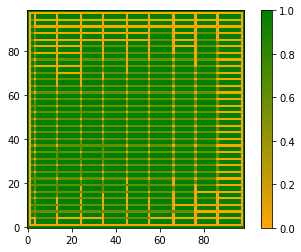

In [23]:
import numpy as np
filein = "/content/gdrive/Shareddrives/Winter Simulation 2021/Layout_updated_2021 (1).csv"
data = np.loadtxt(open(filein, "rb"), delimiter=",")
#print(data)
maze1=np.array(data)
maze1 = np.where(maze1 == 100, 1, maze1)
maze1 = np.where(maze1 == -1, 1, maze1)
maze1 = np.where(maze1 == 200, 1, maze1)
maze1 = np.where(maze1 == 50, 0, maze1)


Zone_total=[0]*(zone+1)
trip=-1
for re in result_P:
      #print(re)
      print(type(re))
      print(len(re))
      c=-1
      trip=trip+1
      if (trip/2)==0:
        Zone_temp=[0]*(zone+1)
        for r in re:
            c=c+1
            #print(r)
            if r==1:
                Zone_total[c]=Zone_total[c]+1
                Zone_temp[c]=1
      if (trip/2)!=0:
        for r in re:
            c=c+1
            if r==1:
              if (Zone_temp[c]!=1):
                Zone_total[c]=Zone_total[c]+1

print(sum(Zone_total))

counter=-1

key=[]
for z in Zone_total:
  counter=counter+1
  if z>=1:
     #val=zones_dictionary.get(a)
     key.append(next(((k,i) for (k,i) in zones_dictionary if zones_dictionary[(k,i)] == counter), None))
     #zones_dictionary.keys()[zones_dictionary.values(counter)]
     for i in zones_dictionary:
       #print(i)
       if zones_dictionary[i]==counter:
         key.append(i)


maze_2=maze1
print(key)
for k in key:
  maze_2[k]=0.6

from matplotlib import pyplot
import matplotlib as mpl

fig = pyplot.figure(2)

cmap2 = mpl.colors.LinearSegmentedColormap.from_list('my_colormap',
                                           ['orange','green'],
                                           256)

img2 = pyplot.imshow(maze_2,interpolation='nearest',
                    cmap = cmap2,
                    origin='lower')

pyplot.colorbar(img2,cmap=cmap2)

fig.savefig("/content/gdrive/Shareddrives/Winter Simulation 2021/image_test_more_than_orequal3.png")

First we try to avoid any zone that has vehicles in it 
Then we try to avoid zones with 2 or more vehicles
if not we try to avoid zones with 3 or more vehicles
Calculate the time taken 
How ?
Factor used-
If 1 other vehicle- 
Trip time is increased to 1.2 times
If 2 other vehicles -
Trip time is increased to 1.4 times
If 3 or more vehicles-
Trip time increased to 2 times 

1.Randomly generate a start and end point \\
2.Find the path using A* \\
3.Check which zones it passes through & calculate the time taken to reach goal using the above matrix \\
4.Try to avoid all other vehicles - look at time taken \\
5.Try to avoid zones with 2 or more vehicles- calculate the time taken \\
6.Try to avoid zones with 3 or more vehicles -calculate the time taken  \\

In [24]:
pip install tqdm

In [25]:
Zone_total=[0]*(zone+1)
trip=-1
for re in result_P:
      #print(re)
      print(type(re))
      print(len(re))
      c=-1
      trip=trip+1
      if (trip/2)==0:
        Zone_temp=[0]*(zone+1)
        for r in re:
            c=c+1
            #print(r)
            if r==1:
                Zone_total[c]=Zone_total[c]+1
                Zone_temp[c]=1
      if (trip/2)!=0:
        for r in re:
            c=c+1
            if r==1:
              if (Zone_temp[c]!=1):
                Zone_total[c]=Zone_total[c]+1

print(sum(Zone_total))

<class 'numpy.ndarray'>
1044
<class 'numpy.ndarray'>
1044
<class 'numpy.ndarray'>
1044
<class 'numpy.ndarray'>
1044
<class 'numpy.ndarray'>
1044
<class 'numpy.ndarray'>
1044
<class 'numpy.ndarray'>
1044
<class 'numpy.ndarray'>
1044
<class 'numpy.ndarray'>
1044
<class 'numpy.ndarray'>
1044
<class 'numpy.ndarray'>
1044
<class 'numpy.ndarray'>
1044
<class 'numpy.ndarray'>
1044
<class 'numpy.ndarray'>
1044
457


In [26]:
import pandas as pd
# load the dataset
import pickle
import numpy as np
import keras

#pickle_off = open("/content/gdrive/Shareddrives/Winter Simulation 2021/data_for_pathplanning4.pkl","rb")
pickle_off = open("/content/gdrive/Shareddrives/Winter Simulation 2021/data_for_pathplanning6_25_2021_7V.pkl","rb")
emp = pickle.load(pickle_off)
print(len(emp[0]))
arr = np.asarray(emp)
X_P=np.array(emp[:2][:][:])
y_P=np.array(emp[2][:][:])
X_P=X_P.reshape(len(X_P[0]),len(X_P[0][0]),len(X_P))
y_P=y_P.reshape(len(y_P),len(y_P[0]))


arr = np.asarray(emp)

  
X_P=np.array(emp[:2][:][:])
y_P=np.array(emp[2][:][:])


X_P=X_P.reshape(len(X_P[0]),len(X_P[0][0]),len(X_P))
y_P=y_P.reshape(len(y_P),len(y_P[0]))


arr=y_P
shape = arr.shape
result_P = np.zeros(shape)
for x in range(0, shape[0]):
  for z in range(0, shape[1]):
        if arr[x][z] >= 1:
            result_P[x][z] = 1
        else:
          result_P[x][z] = 0


import numpy as np
filein = "/content/gdrive/Shareddrives/Winter Simulation 2021/Layout_updated_2021 (1).csv"
data = np.loadtxt(open(filein, "rb"), delimiter=",")
#print(data)
maze1=np.array(data)
maze1 = np.where(maze1 == 100, 1, maze1)
maze1 = np.where(maze1 == -1, 1, maze1)
maze1 = np.where(maze1 == 200, 1, maze1)
maze1 = np.where(maze1 == 50, 0, maze1)


Zone_total=[0]*(zone+1)
trip=-1
for re in result_P:
      #print(re)
      print(type(re))
      print(len(re))
      c=-1
      trip=trip+1
      if (trip/2)==0:
        Zone_temp=[0]*(zone+1)
        for r in re:
            c=c+1
            #print(r)
            if r==1:
                Zone_total[c]=Zone_total[c]+1
                Zone_temp[c]=1
      if (trip/2)!=0:
        for r in re:
            c=c+1
            if r==1:
              if (Zone_temp[c]!=1):
                Zone_total[c]=Zone_total[c]+1



fig.savefig("/content/gdrive/Shareddrives/Winter Simulation 2021/image_test_more_than_orequal3.png")





10
<class 'numpy.ndarray'>
1046
<class 'numpy.ndarray'>
1046
<class 'numpy.ndarray'>
1046
<class 'numpy.ndarray'>
1046
<class 'numpy.ndarray'>
1046
<class 'numpy.ndarray'>
1046
<class 'numpy.ndarray'>
1046
<class 'numpy.ndarray'>
1046
<class 'numpy.ndarray'>
1046
<class 'numpy.ndarray'>
1046


In [ ]:
#Step1
from tqdm.auto import tqdm
m1=0
m2=0
m1_list=[]
m2_list=[]
not_giving_up=0
time_list_no_traffic_avoidance=[]
time_list_Traffic_Avoidance=[]
for not_giving_up in tqdm(range(10)):
              number_of_times_all_vehicles_can_be_avoided =0
              number_of_times_its_useful =0
              trial_list=[]
              sum_total_time=0
              distance_total=0
              time_list_No_Avoidance=[]
              distance_list_No_Avoidance=[]
              time_list_Traffic_Avoidance=[]
              distance_list_Traffic_Avoidance=[]
              #with tqdm(total=100, position=0, leave=True) as pbar:
              for trial in range(100):


                                    data_points=1
                                    ip_1_s=[]
                                    ip_2_f=[]
                                    op_1_t=[]
                                    count_data=1
                                    distance_travelled_by_Native_AStar=[]
                                    time_taken_by_Native_AStar=[]
                                    distance_travelled_avoiding1V=[]
                                    time_taken_avoiding1V=[]
                                    distance_travelled_avoiding2V=[]
                                    time_taken_avoiding2V=[]
                                    distance_travelled_avoiding3V=[]
                                    time_taken_avoiding3V=[]
                                    while count_data<2:
                                                    count_data=count_data+1
                                                    #data_points=1
                                                    for N in range (0,data_points): 
                                                      ip_1_s=[]
                                                      ip_2_f=[]
                                                      op_1_t=[]
                                                      n=1
                                                      A1_n1_path=Decentralized_multi_agent_paths(n)
                                                      #writing number of vehicles begning their trip in each zone
                                                      for A1 in A1_n1_path:
                                                        A1_n=[A1]
                                                        Zone_start_trip=[0]*(zone+1)
                                                        Zone_finish_trip=[0]*(zone+1)
                                                        #Zone_rack=[0]*(zone+1)
                                                        for a in A1_n:

                                                          temp_init=list(a[0])

                                                          temp_init=tuple(temp_init)
                                                          init=zones_dictionary.get(temp_init)

                                                          Zone_start_trip[init]=Zone_start_trip[init]+1

                                                        #writing number of vehicles ending their trip in each zone
                                                        for A1 in A1_n:
                                                          A1_n=[A1]

                                                          temp_final=list(a[-1])

                                                          temp_final=tuple(temp_final)
                                                          #print(temp_final)
                                                          final=zones_dictionary.get(temp_final)
                                                          #print(final)
                                                          Zone_finish_trip[final]=Zone_finish_trip[final]+1
                                                        #writing number of vehicles that go to a deck in a zone as intermediate point 
                                                    
                                                        #writing zone busy-ness
                                                            
                                                        Z_n_b=Zone_business(A1_n)

                                                        ip_1_s.append(Zone_start_trip)
                                                      
                                                        ip_2_f.append(Zone_finish_trip)
                                                        
                                                        #ip_3.append(Zone_rack)
                                                      
                                                        op_1_t.append(Z_n_b)
                                                  
                                                    list_features_op_testcase=[]
                                                    list_features_op_testcase.append(ip_1_s)
                                                    list_features_op_testcase.append(ip_2_f)
                                                    #list_features_op.append(ip_3)
                                                    list_features_op_testcase.append(op_1_t)

                                                    import pickle
                                                    with open('/content/gdrive/Shareddrives/Winter Simulation 2021/data_for_pathplanning_test_case2.pkl', 'wb') as f:
                                                          pickle.dump(list_features_op_testcase, f)
                                                    with open('/content/gdrive/Shareddrives/Winter Simulation 2021/start_and_end_point_test_case2.pkl', 'wb') as f:
                                                          pickle.dump(A1_n1_path, f)
                                                    
                                                    import pickle
                                                    pickle_off = open("/content/gdrive/Shareddrives/Winter Simulation 2021/data_for_pathplanning_test_case2.pkl","rb")
                                                    emp = pickle.load(pickle_off)

                                                    op_1_t=emp[2][:][:]
                                                    #print(len(op_1_t))
                                                    #print(len(op_1_t[0]))
                                                    arr=np.array(op_1_t)
                                                    shape = arr.shape
                                                    zone_traversed= np.zeros(shape)
                                                    for x in range(0, shape[0]):
                                                      for z in range(0, shape[1]):
                                                            if arr[x][z] >= 1:
                                                                zone_traversed[x][z] = 1
                                                            else:
                                                              zone_traversed[x][z] = 0
                                                    #print(len(zone_traversed))

                                                    o=[sum(sum(zone_traversed))]
                                                    distance_travelled_by_Native_AStar.append(sum(sum(zone_traversed)))
                                                    time_A_Star=sum(sum(zone_traversed))
                                                    for zone_traversed_counter in zone_traversed:
                                                        for i in range(0,len(zone_traversed[0])):
                                                          if zone_traversed_counter[i]!=0:
                                                              if Zone_total[i]==1:
                                                                time_A_Star=time_A_Star+2
                                                              if Zone_total[i]==2:    
                                                                time_A_Star=time_A_Star+3
                                                              if Zone_total[i]==3:
                                                                time_A_Star=time_A_Star+4
                                                              else:
                                                                time_A_Star=time_A_Star+Zone_total[i]+1
                                                    time_taken_by_Native_AStar.append(time_A_Star)


                                                    counter=-1
                                                    time_A_Star=0


                                                    key=[]


                                                    for z in Zone_total:
                                                      counter=counter+1
                                                      if z>=1:
                                                        #val=zones_dictionary.get(a)
                                                        key.append(next(((k,i) for (k,i) in zones_dictionary if zones_dictionary[(k,i)] == counter), None))
                                                        #zones_dictionary.keys()[zones_dictionary.values(counter)]
                                                        for i in zones_dictionary:
                                                          #print(i)
                                                          if zones_dictionary[i]==counter:
                                                            key.append(i)


                                                    maze_2=maze1
                                                    #print(key)
                                                    for k in key:
                                                      maze_2[k]=1





                                                    from tqdm import tqdm
                                                    from google.colab import files
                                                    import random
                                                    import pandas as pd
                                                    import csv 
                                                    import json
                                                    #Start and end positions 
                                                    #More specifically - start , shelf, shelf,dock 
                                                    init=[]
                                                    final=[]
                                                    #print(A1_n1_path)
                                                    for A1 in A1_n1_path:
                                                        A1_n=[A1]
                                                        #Zone_rack=[0]*(zone+1)
                                                        for a in A1_n:
                                                          #print(a)
                                                          #print(a[0])
                                                          init.append(a[0])
                                                          final.append(a[-1])
                                                    #def data_generator_for_nn(data_points):
                                                    data_points=1
                                                    ip_1_avoid2=[]
                                                    ip_2_avoid2=[]
                                                    op_1_avoid2=[]
                                                    for N in range (0,data_points): 
                                                      #print(n)
                                                      #n = random. randint(10,15) #randomly generated number between 2 to 20 
                                                      n=1
                                                      A1_n1_avoid2=[]
                                                      test_planner = PathPlanner(maze_2, True) 
                                                      #print(init)
                                                      start=init[0]
                                                      #print(type(start))
                                                      start=list(start)
                                                      temp=start
                                                      start[1]=temp[0]
                                                      start[0]=temp[1]
                                                      end=final[0]
                                                      temp1=end
                                                      end=list(end)
                                                      end[1]=temp1[0]
                                                      end[0]=temp1[1]
                                                      a1= test_planner.a_star(start,end) 
                                                      #print(type(a1))

                                                      start=init[1]
                                                      start=list(start)
                                                      temp=start
                                                      start[1]=temp[0]
                                                      start[0]=temp[1]
                                                      end=final[1]
                                                      temp1=end
                                                      end=list(end)
                                                      end[1]=temp1[0]
                                                      end[0]=temp1[1]
                                                      a2= test_planner.a_star(start,end)  
                                                      A1_n1_avoid2.append(a1)
                                                      A1_n1_avoid2.append(a2)
                                                      #print(A1_n1_avoid2)
                                                      #print(len(A1_n1_avoid2))
                                                      #print(len(A1_n1_avoid2[0]))
                                                      check=1
                                                      for A_check_empty in A1_n1_avoid2:
                                                        if A_check_empty==[] : 
                                                          check=0
                                                        else:
                                                          check=check*1
                                                      if (check==1):
                                                        if ((A1_n1_avoid2[0])==[] ) and (len(A1_n1_avoid2[1]==0)):
                                                              #writing number of vehicles begning their trip in each zone
                                                              for A1 in A1_n1_avoid2:
                                                                #print(A1)
                                                                A1_n=[A1]
                                                                Zone_start_trip=[0]*(zone+1)
                                                                Zone_finish_trip=[0]*(zone+1)
                                                                #Zone_rack=[0]*(zone+1)
                                                                for a in A1_n1_avoid2:
                                                                  #print(a)
                                                                  #print(a[0])
                                                                  temp_init=list(a[0])
                                                                  #temp=temp_init[0]
                                                                  #temp_init[0]=temp_init[1]
                                                                  #temp_init[1]=temp
                                                                  temp_init=tuple(temp_init)
                                                                  init=zones_dictionary.get(temp_init)
                                                                  #print(init)
                                                                  #print(data[init])
                                                                  Zone_start_trip[init]=Zone_start_trip[init]+1

                                                                #writing number of vehicles ending their trip in each zone
                                                                for A1 in A1_n1_avoid2:
                                                                  A1_n=[A1]
                                                                  #print(a[-1])
                                                                  temp_final=list(a[-1])
                                                                  #temp=temp_final[0]
                                                                  #temp_final[0]=temp_final[1]
                                                                  #temp_final[1]=temp
                                                                  #temp_final=tuple(temp_final)
                                                                  temp_final=tuple(temp_final)
                                                                  #print(temp_final)
                                                                  final=zones_dictionary.get(temp_final)
                                                                  #print(final)
                                                                  Zone_finish_trip[final]=Zone_finish_trip[final]+1
                                                                #writing number of vehicles that go to a deck in a zone as intermediate point 

                                                                #writing zone busy-ness
                                                                    
                                                                Z_n=Zone_business(A1_n1_avoid2)

                                                                ip_1_avoid2.append(Zone_start_trip)
                                                              
                                                                ip_2_avoid2.append(Zone_finish_trip)
                                                                
                                                                #ip_3.append(Zone_rack)
                                                              
                                                                op_1_avoid2.append(Z_n)

                                                    if ((A1_n1_avoid2[0]!=[]) and (A1_n1_avoid2[1]!=[])):       
                                                              list_features_op_avoid2=[]
                                                              list_features_op_avoid2.append(ip_1_avoid2)
                                                              list_features_op_avoid2.append(ip_2_avoid2)
                                                              #list_features_op.append(ip_3)
                                                              list_features_op_avoid2.append(op_1_avoid2)
                                                    if ((A1_n1_avoid2[0]==[]) or (A1_n1_avoid2[1]==[])):
                                                        print("no path found")
                                                        distance_travelled_avoiding1V.append(0)
                                                        time_taken_avoiding1V.append(0)
                                                    else:
                                                      arr=np.array(op_1_avoid2)
                                                      shape = arr.shape
                                                      zone_traversed_1= np.zeros(shape)
                                                      for x in range(0, shape[0]):
                                                        for z in range(0, shape[1]):
                                                              if arr[x][z] >= 1:
                                                                  zone_traversed_1[x][z] = 1
                                                              else:
                                                                zone_traversed_1[x][z] = 0

                                                      #print(zone_traversed_1.shape)
                                                      time_taken_A_Star_avoid2=sum(zone_traversed_1)
                                                      distance_travelled_avoiding1V.append(time_taken_A_Star_avoid2)
                                                      #print(time_taken_A_Star_avoid2)


                                                      for zone_traversed_1 in op_1_avoid2:
                                                            for i in range(0,len(zone_traversed[0])):
                                                              if zone_traversed_counter[i]!=0:
                                                                  if Zone_total[i]==1:
                                                                    time_taken_A_Star_avoid2=time_taken_A_Star_avoid2+2
                                                                  if Zone_total[i]==2:
                                                                    time_taken_A_Star_avoid2=time_taken_A_Star_avoid2+3
                                                                  if Zone_total[i]==3:
                                                                    time_taken_A_Star_avoid2=time_taken_A_Star_avoid2+4
                                                                  else:
                                                                    time_taken_A_Star_avoid2=time_taken_A_Star_avoid2+Zone_total[i]+1

                                                      
                                                      time_taken_avoiding1V.append(time_taken_A_Star_avoid2)
                                                      del(time_taken_A_Star_avoid2)


















                                                    import numpy as np
                                                    filein = "/content/gdrive/Shareddrives/Winter Simulation 2021/Layout_updated_2021 (1).csv"
                                                    data = np.loadtxt(open(filein, "rb"), delimiter=",")
                                                    #print(data)
                                                    maze1=np.array(data)
                                                    maze1 = np.where(maze1 == 100, 1, maze1)
                                                    maze1 = np.where(maze1 == -1, 1, maze1)
                                                    maze1 = np.where(maze1 == 200, 1, maze1)
                                                    maze1 = np.where(maze1 == 50, 0, maze1)


                                                    Zone_total=[0]*(zone+1)
                                                    trip=-1
                                                    for re in result_P:
                                                          #print(re)
                                                          #print(type(re))
                                                          #print(len(re))
                                                          c=-1
                                                          trip=trip+1
                                                          if (trip/2)==0:
                                                            Zone_temp=[0]*(zone+1)
                                                            for r in re:
                                                                c=c+1
                                                                #print(r)
                                                                if r==1:
                                                                    Zone_total[c]=Zone_total[c]+1
                                                                    Zone_temp[c]=1
                                                          if (trip/2)!=0:
                                                            for r in re:
                                                                c=c+1
                                                                if r==1:
                                                                  if (Zone_temp[c]!=1):
                                                                    Zone_total[c]=Zone_total[c]+1
                                                    

                                                    key=[]
                                                    counter=-1
                                                    for z in Zone_total:
                                                      counter=counter+1
                                                      if z>=2:
                                                        #val=zones_dictionary.get(a)
                                                        key.append(next(((k,i) for (k,i) in zones_dictionary if zones_dictionary[(k,i)] == counter), None))
                                                        #zones_dictionary.keys()[zones_dictionary.values(counter)]
                                                        for i in zones_dictionary:
                                                          #print(i)
                                                          if zones_dictionary[i]==counter:
                                                            key.append(i)


                                                    maze_3=maze1
                                                    #print(key)
                                                    for k in key:
                                                      maze_3[k]=1

                                                    from tqdm import tqdm
                                                    from google.colab import files
                                                    import random
                                                    import pandas as pd
                                                    import csv 
                                                    import json
                                                    #Start and end positions 
                                                    #More specifically - start , shelf, shelf,dock 
                                                    init=[]
                                                    final=[]
                                                    #print(A1_n1_path)
                                                    for A1 in A1_n1_path:
                                                        A1_n=[A1]
                                                        #Zone_rack=[0]*(zone+1)
                                                        for a in A1_n:
                                                          #print(a)
                                                          #print(a[0])
                                                          init.append(a[0])
                                                          final.append(a[-1])
                                                    #def data_generator_for_nn(data_points):
                                                    data_points=1
                                                    ip_1_avoid2=[]
                                                    ip_2_avoid2=[]
                                                    op_1_avoid2=[]
                                                    for N in range (0,data_points): 
                                                      #print(n)
                                                      #n = random. randint(10,15) #randomly generated number between 2 to 20 
                                                      n=1
                                                      A1_n1_avoid2=[]
                                                      test_planner = PathPlanner(maze_3, True) 
                                                      #print(init)
                                                      start=init[0]
                                                      #print(type(start))
                                                      start=list(start)
                                                      temp=start
                                                      start[1]=temp[0]
                                                      start[0]=temp[1]
                                                      end=final[0]
                                                      temp1=end
                                                      end=list(end)
                                                      end[1]=temp1[0]
                                                      end[0]=temp1[1]
                                                      a1= test_planner.a_star(start,end) 
                                                      #print(type(a1))

                                                      start=init[1]
                                                      start=list(start)
                                                      temp=start
                                                      start[1]=temp[0]
                                                      start[0]=temp[1]
                                                      end=final[1]
                                                      temp1=end
                                                      end=list(end)
                                                      end[1]=temp1[0]
                                                      end[0]=temp1[1]
                                                      a2= test_planner.a_star(start,end)  
                                                      A1_n1_avoid2.append(a1)
                                                      A1_n1_avoid2.append(a2)
                                                      #print(A1_n1_avoid2)
                                                      #print(len(A1_n1_avoid2))
                                                      check=1
                                                      for A_check_empty in A1_n1_avoid2:
                                                        if A_check_empty==[] : 
                                                          check=0
                                                        else:
                                                          check=check*1
                                                      if ((A1_n1_avoid2[0]!=-1 ) and (A1_n1_avoid2[1]!=-1)):
                                                        if (check==1):
                                                          if ((A1_n1_avoid2[0]!=[] ) and (A1_n1_avoid2[1]!=[])):
                                                              #writing number of vehicles begning their trip in each zone
                                                              for A1 in A1_n1_avoid2:
                                                                #print(A1)
                                                                A1_n=[A1]
                                                                Zone_start_trip=[0]*(zone+1)
                                                                Zone_finish_trip=[0]*(zone+1)
                                                                #Zone_rack=[0]*(zone+1)
                                                                for a in A1_n:
                                                                  #print(a)
                                                                  #print(a[0])
                                                                  temp_init=list(a[0])
                                                                  #temp=temp_init[0]
                                                                  #temp_init[0]=temp_init[1]
                                                                  #temp_init[1]=temp
                                                                  temp_init=tuple(temp_init)
                                                                  init=zones_dictionary.get(temp_init)
                                                                  #print(init)
                                                                  #print(data[init])
                                                                  Zone_start_trip[init]=Zone_start_trip[init]+1

                                                                #writing number of vehicles ending their trip in each zone
                                                                for A1 in A1_n:
                                                                  A1_n=[A1]
                                                                  #print(a[-1])
                                                                  temp_final=list(a[-1])
                                                                  #temp=temp_final[0]
                                                                  #temp_final[0]=temp_final[1]
                                                                  #temp_final[1]=temp
                                                                  #temp_final=tuple(temp_final)
                                                                  temp_final=tuple(temp_final)
                                                                  #print(temp_final)
                                                                  final=zones_dictionary.get(temp_final)
                                                                  #print(final)
                                                                  Zone_finish_trip[final]=Zone_finish_trip[final]+1
                                                                #writing number of vehicles that go to a deck in a zone as intermediate point 

                                                                #writing zone busy-ness
                                                                    
                                                                Z_n=Zone_business(A1_n1_avoid2)

                                                                ip_1_avoid2.append(Zone_start_trip)
                                                              
                                                                ip_2_avoid2.append(Zone_finish_trip)
                                                                
                                                                #ip_3.append(Zone_rack)
                                                              
                                                                op_1_avoid2.append(Z_n)

                                                    if (A1_n1_avoid2[0] !=-1 and A1_n1_avoid2[0]!=-1 ):       
                                                              list_features_op_avoid2=[]
                                                              list_features_op_avoid2.append(ip_1_avoid2)
                                                              list_features_op_avoid2.append(ip_2_avoid2)
                                                              #list_features_op.append(ip_3)
                                                              list_features_op_avoid2.append(op_1_avoid2)
                                                    if ((A1_n1_avoid2[0]==-1) or (A1_n1_avoid2[1]==-1)):
                                                        print("no path found")
                                                        distance_travelled_avoiding2V.append(0)
                                                        time_taken_avoiding2V.append(0)
                                                    else:
                                                          arr=np.array(op_1_avoid2)
                                                          shape = arr.shape
                                                          zone_traversed_1= np.zeros(shape)
                                                          for x in range(0, shape[0]):
                                                            for z in range(0, shape[1]):
                                                                  if arr[x][z] >= 1:
                                                                      zone_traversed_1[x][z] = 1
                                                                  else:
                                                                    zone_traversed_1[x][z] = 0

                                                    if (type(A1_n1_avoid2) == 'list' ):   
                                                          time_taken_A_Star_avoid2=sum(sum(zone_traversed_1))
                                                          distance_travelled_avoiding2V.append(time_taken_A_Star_avoid2)
                                                          #print(time_taken_A_Star_avoid2)


                                                          for zone_traversed_1 in op_1_avoid2:
                                                                for i in range(0,len(zone_traversed[0])):
                                                                  if zone_traversed_counter[i]!=0:
                                                                      if Zone_total[i]==1:
                                                                        time_taken_A_Star_avoid2=time_taken_A_Star_avoid2+2
                                                                      if Zone_total[i]==2:
                                                                        time_taken_A_Star_avoid2=time_taken_A_Star_avoid2+3
                                                                      if Zone_total[i]==3:
                                                                          time_taken_A_Star_avoid2=time_taken_A_Star_avoid2+4
                                                                      else:
                                                                          time_taken_A_Star_avoid2=time_taken_A_Star_avoid2+Zone_total[i]+1
                                                          
                                                          time_taken_avoiding2V.append(time_taken_A_Star_avoid2) 
                                                          del(time_taken_A_Star_avoid2)
                                                    #distance_travelled_avoiding3V=[]
                                                    #time_taken_avoiding3V=[]
                                                    else:
                                                      time_taken_A_Star_avoid2=0
                                                      distance_travelled_avoiding2V.append(time_taken_A_Star_avoid2)
                                                      time_taken_avoiding2V.append(time_taken_A_Star_avoid2) 
                                                      #print(time_taken_A_Star_avoid2)


                                                    








                                                    import numpy as np
                                                    filein = "/content/gdrive/Shareddrives/Winter Simulation 2021/Layout_updated_2021 (1).csv"
                                                    data = np.loadtxt(open(filein, "rb"), delimiter=",")
                                                    #print(data)
                                                    maze1=np.array(data)
                                                    maze1 = np.where(maze1 == 100, 1, maze1)
                                                    maze1 = np.where(maze1 == -1, 1, maze1)
                                                    maze1 = np.where(maze1 == 200, 1, maze1)
                                                    maze1 = np.where(maze1 == 50, 0, maze1)


                                                    
                                                    counter=-1

                                                    key=[]
                                                    for z in Zone_total:
                                                      counter=counter+1
                                                      if z >=3:
                                                        #val=zones_dictionary.get(a)
                                                        key.append(next(((k,i) for (k,i) in zones_dictionary if zones_dictionary[(k,i)] == counter), None))
                                                        #zones_dictionary.keys()[zones_dictionary.values(counter)]
                                                        for i in zones_dictionary:
                                                          #print(i)
                                                          if zones_dictionary[i]==counter:
                                                            key.append(i)


                                                    maze_4=maze1
                                                    #print(key)
                                                    for k in key:
                                                      maze_4[k]=1



                                                    from tqdm import tqdm
                                                    from google.colab import files
                                                    import random
                                                    import pandas as pd
                                                    import csv 
                                                    import json
                                                    #Start and end positions 
                                                    #More specifically - start , shelf, shelf,dock 
                                                    init=[]
                                                    final=[]
                                                    #print(A1_n1_path)
                                                    for A1 in A1_n1_path:
                                                        A1_n=[A1]
                                                        #Zone_rack=[0]*(zone+1)
                                                        for a in A1_n:
                                                          #print(a)
                                                          #print(a[0])
                                                          init.append(a[0])
                                                          final.append(a[-1])
                                                    #def data_generator_for_nn(data_points):
                                                    data_points=1
                                                    ip_1_avoid2=[]
                                                    ip_2_avoid2=[]
                                                    op_1_avoid2=[]
                                                    for N in range (0,data_points): 
                                                      #print(n)
                                                      #n = random. randint(10,15) #randomly generated number between 2 to 20 
                                                      n=1
                                                      A1_n1_avoid2=[]
                                                      test_planner1 = PathPlanner(maze_4, True) 
                                                      #print(init)
                                                      start=init[0]
                                                      #print(type(start))
                                                      start=list(start)
                                                      temp=start
                                                      start[1]=temp[0]
                                                      start[0]=temp[1]
                                                      end=final[0]
                                                      temp1=end
                                                      end=list(end)
                                                      end[1]=temp1[0]
                                                      end[0]=temp1[1]
                                                      a1= test_planner1.a_star(start,end) 
                                                      #print(type(a1))

                                                      start=init[1]
                                                      start=list(start)
                                                      temp=start
                                                      start[1]=temp[0]
                                                      start[0]=temp[1]
                                                      end=final[1]
                                                      temp1=end
                                                      end=list(end)
                                                      end[1]=temp1[0]
                                                      end[0]=temp1[1]
                                                      a2= test_planner1.a_star(start,end)  
                                                      A1_n1_avoid2.append(a1)
                                                      A1_n1_avoid2.append(a2)
                                                      #print(A1_n1_avoid2)
                                                      #print(len(A1_n1_avoid2))
                                                      check=1
                                                      for A_check_empty in A1_n1_avoid2:
                                                        if A_check_empty==[] : 
                                                          check=0
                                                        else:
                                                          check=check*1
                                                      if (check==1):
                                                        if (A1_n1_avoid2 !=[] and A1_n1_avoid2 !=-1):
                                                          #print(A1_n1_avoid2)
                                                          if (A1_n1_avoid2[0] !=-1 and A1_n1_avoid2[1] !=-1):
                                                            #print(A1_n1_avoid2)
                                                            if ((len(A1_n1_avoid2[0])!=0 ) and (len(A1_n1_avoid2[1])!=0)):
                                                              #writing number of vehicles begning their trip in each zone
                                                              for A1 in A1_n1_avoid2:
                                                                #print(A1)
                                                                A1_n=[A1]
                                                                Zone_start_trip=[0]*(zone+1)
                                                                Zone_finish_trip=[0]*(zone+1)
                                                                #Zone_rack=[0]*(zone+1)
                                                                for a in A1_n:
                                                                  #print(a)
                                                                  #print(a[0])
                                                                  temp_init=list(a[0])
                                                                  #temp=temp_init[0]
                                                                  #temp_init[0]=temp_init[1]
                                                                  #temp_init[1]=temp
                                                                  temp_init=tuple(temp_init)
                                                                  init=zones_dictionary.get(temp_init)
                                                                  #print(init)
                                                                  #print(data[init])
                                                                  Zone_start_trip[init]=Zone_start_trip[init]+1

                                                                #writing number of vehicles ending their trip in each zone
                                                                for A1 in A1_n1_avoid2:
                                                                  A1_n=[A1]
                                                                  #print(a[-1])
                                                                  temp_final=list(a[-1])
                                                                  #temp=temp_final[0]
                                                                  #temp_final[0]=temp_final[1]
                                                                  #temp_final[1]=temp
                                                                  #temp_final=tuple(temp_final)
                                                                  temp_final=tuple(temp_final)
                                                                  #print(temp_final)
                                                                  final=zones_dictionary.get(temp_final)
                                                                  #print(final)
                                                                  Zone_finish_trip[final]=Zone_finish_trip[final]+1
                                                                #writing number of vehicles that go to a deck in a zone as intermediate point 

                                                                #writing zone busy-ness
                                                                    
                                                                Z_n=Zone_business(A1_n1_avoid2)

                                                                ip_1_avoid2.append(Zone_start_trip)
                                                              
                                                                ip_2_avoid2.append(Zone_finish_trip)
                                                                
                                                                #ip_3.append(Zone_rack)
                                                              
                                                                op_1_avoid2.append(Z_n)
                                                    if (A1_n1_avoid2!=-1 and A1_n1_avoid2!=[]):
                                                      if (A1_n1_avoid2[0]!=-1 and A1_n1_avoid2[1]!=-1):
                                                        if ((len(A1_n1_avoid2[0])!=0) and (len(A1_n1_avoid2[1])!=0)):       
                                                              list_features_op_avoid2=[]
                                                              list_features_op_avoid2.append(ip_1_avoid2)
                                                              list_features_op_avoid2.append(ip_2_avoid2)
                                                              #list_features_op.append(ip_3)
                                                              list_features_op_avoid2.append(op_1_avoid2)
                                                    
                                                    if (A1_n1_avoid2[0]!=-1 and A1_n1_avoid2[1]!=-1):
                                                      if ((len(A1_n1_avoid2[0])==0) or (len(A1_n1_avoid2[1])==0)):
                                                        print("no path found")
                                                        distance_travelled_avoiding2V.append(0)
                                                        time_taken_avoiding2V.append(0)
                                                    else:
                                                      arr=np.array(op_1_avoid2)
                                                      shape = arr.shape
                                                      zone_traversed_1= np.zeros(shape)
                                                      for x in range(0, shape[0]):
                                                        for z in range(0, shape[1]):
                                                              if arr[x][z] >= 1:
                                                                  zone_traversed_1[x][z] = 1
                                                              else:
                                                                zone_traversed_1[x][z] = 0


                                                      if (zone_traversed_1 != []):
                                                        time_taken_A_Star_avoid2=sum(sum(zone_traversed_1))
                                                        
                                                      else:
                                                        time_taken_A_Star_avoid2=0
                                                      distance_travelled_avoiding3V.append(time_taken_A_Star_avoid2)
                                                      #print(time_taken_A_Star_avoid2)

                                                      for zone_traversed_1 in op_1_avoid2:
                                                            for i in range(0,len(zone_traversed[0])):
                                                              if zone_traversed_counter[i]!=0:
                                                                  if Zone_total[i]==1:
                                                                    time_taken_A_Star_avoid2=time_taken_A_Star_avoid2+2
                                                                  if Zone_total[i]==2:
                                                                    time_taken_A_Star_avoid2=time_taken_A_Star_avoid2+3
                                                                  if Zone_total[i]==3:
                                                                    time_taken_A_Star_avoid2=time_taken_A_Star_avoid2+3
                                                                  else:
                                                                    time_taken_A_Star_avoid2=time_taken_A_Star_avoid2+Zone_total[i]+1

                                                    
                                                      time_taken_avoiding3V.append(time_taken_A_Star_avoid2) 


                                    #print(distance_travelled_by_Native_AStar)
                                    #print(time_taken_by_Native_AStar)
                                    #print(distance_travelled_avoiding1V)
                                    #print(time_taken_avoiding1V)
                                    #print(distance_travelled_avoiding2V)
                                    #print(time_taken_avoiding2V)
                                    #print(distance_travelled_avoiding3V)
                                    #print(time_taken_avoiding3V)

                                    #if ((time_taken_by_Native_AStar > time_taken_avoiding2V)):
                                    #number_of_times_its_useful = number_of_times_its_useful +1 
                                    time_list_no_traffic_avoidance.append(time_taken_by_Native_AStar[0])
                                    distance_list_No_Avoidance.append(distance_travelled_by_Native_AStar[0])
                                    if (time_taken_by_Native_AStar > time_taken_avoiding3V) and (time_taken_avoiding3V !=0) and (time_taken_avoiding3V !=[]):
                                        #if (time_taken_avoiding2V >= time_taken_avoiding3V):
                                        number_of_times_its_useful = number_of_times_its_useful +1
                                        sum_total_time= sum_total_time+(time_taken_by_Native_AStar[0]-time_taken_avoiding3V[0])
                                        distance_total=distance_total+(distance_travelled_avoiding3V-distance_travelled_by_Native_AStar[0])
                                        time_list_No_Avoidance.append(time_taken_by_Native_AStar[0])
                                        distance_list_No_Avoidance.append(distance_travelled_by_Native_AStar[0])
                                        time_list_Traffic_Avoidance.append(time_taken_avoiding3V[0])
                                        distance_list_Traffic_Avoidance.append(distance_travelled_avoiding3V)
                                    else:
                                      if ((time_taken_by_Native_AStar> time_taken_avoiding2V) and (time_taken_avoiding2V !=0) and (time_taken_avoiding2V !=[])):
                                        number_of_times_its_useful = number_of_times_its_useful +1
                                        sum_total_time= sum_total_time+(time_taken_by_Native_AStar[0]-time_taken_avoiding2V[0])
                                        distance_total=distance_total+(distance_travelled_avoiding3V-distance_travelled_by_Native_AStar[0])
                                        distance_total=distance_total+(distance_travelled_avoiding3V-distance_travelled_by_Native_AStar[0])
                                        #time_list_No_Avoidance.append(time_taken_by_Native_AStar[0])
                                        #distance_list_No_Avoidance.append(distance_travelled_by_Native_AStar[0])
                                        time_list_Traffic_Avoidance.append(time_taken_avoiding2V)
                                        distance_list_Traffic_Avoidance.append(distance_travelled_avoiding2V)
                                      else :
                                        #time_list_No_Avoidance.append(time_taken_by_Native_AStar[0])
                                        #distance_list_No_Avoidance.append(distance_travelled_by_Native_AStar[0])
                                        if ((time_taken_avoiding3V> time_taken_avoiding2V) and (time_taken_avoiding2V !=0) and (time_taken_avoiding2V !=[])):
                                            time_list_Traffic_Avoidance.append(time_taken_avoiding2V)
                                            distance_list_Traffic_Avoidance.append(distance_travelled_avoiding2V)
                                        else:
                                          time_list_Traffic_Avoidance.append(time_taken_avoiding3V)
                                          distance_list_Traffic_Avoidance.append(distance_travelled_avoiding3V)

                                      
                                    
                                    
              #if (time_taken_avoiding1V != [0]):
              #number_of_times_all_vehicles_can_be_avoided = number_of_times_all_vehicles_can_be_avoided +1
              #trial_list.append(trial)
                                    

              print(number_of_times_its_useful)
              print(trial_list)

              from statistics import mean
              print(mean(time_list_no_traffic_avoidance))
              m1=(mean(time_list_no_traffic_avoidance))
              m1_list.append(m1)
              #print(mean(distance_list_No_Avoidance))
              print(mean(time_list_Traffic_Avoidance))
              m2=(mean(time_list_Traffic_Avoidance))
              m2_list.append(m2)
              not_giving_up=not_giving_up+1
              print(not_giving_up)
              if (m1>m2):
                break

no path found
no path found
no path found
no path found
no path found
no path found
no path found
no path found
no path found
no path found
no path found
100
[]
223.28


TypeError: ignored

In [64]:
print(zone_number_of_cells_dict)

[1, 1, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 9, 1, 10, 1, 1, 1, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 9, 1, 10, 1, 1, 1, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 9, 1, 10, 1, 1, 1, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 9, 1, 10, 1, 1, 1, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 9, 1, 10, 1, 1, 1, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 9, 1, 10, 1, 1, 1, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 9, 1, 10, 1, 1, 1, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 9, 1, 10, 1, 1, 1, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 9, 1, 10, 1, 1, 1, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 9, 1, 10, 1, 1, 1, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 9, 1, 10, 1, 1, 1, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 9, 1, 10, 1, 1, 1, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 9, 1, 10, 1, 1, 1, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 9, 1, 10, 1, 1, 1, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 10, 1, 9, 1, 9, 1, 1

In [27]:

from tqdm.auto import tqdm
m1=0
m2=0
m1_list=[]
m2_list=[]
not_giving_up=0
time_list_no_traffic_avoidance=[]
time_list_Traffic_Avoidance=[]
seed_random=-1

for not_giving_up in tqdm(range(120)):
              number_of_times_all_vehicles_can_be_avoided =0
              number_of_times_its_useful =0
              trial_list=[]
              sum_total_time=0
              distance_total=0
              time_list_No_Avoidance=[]
              distance_list_No_Avoidance=[]
              time_list_Traffic_Avoidance=[]
              distance_list_Traffic_Avoidance=[]
              no_of_vehicles_noT=[]
              no_of_vehicles_T=[]
              #with tqdm(total=100, position=0, leave=True) as pbar:
              seed_random=seed_random+1
              random.seed(seed_random)
              for trial in range(100):
                                #Step1
                                from tqdm import tqdm
                                data_points=1
                                ip_1_s=[]
                                ip_2_f=[]
                                op_1_t=[]
                                count_data=1
                                distance_travelled_by_Native_AStar=[]
                                time_taken_by_Native_AStar=[]
                                distance_travelled_avoiding1V=[]
                                time_taken_avoiding1V=[]
                                distance_travelled_avoiding2V=[]
                                time_taken_avoiding2V=[]
                                distance_travelled_avoiding3V=[]
                                time_taken_avoiding3V=[]
                                while count_data<2:
                                                count_data=count_data+1
                                                #data_points=1
                                                for N in tqdm(range (0,data_points)): 
                                                  ip_1_s=[]
                                                  ip_2_f=[]
                                                  op_1_t=[]
                                                  n=1
                                                  A1_n1_path=Decentralized_multi_agent_paths(n)
                                                  #writing number of vehicles begning their trip in each zone
                                                  for A1 in A1_n1_path:
                                                    A1_n=[A1]
                                                    Zone_start_trip=[0]*(zone+1)
                                                    Zone_finish_trip=[0]*(zone+1)
                                                    #Zone_rack=[0]*(zone+1)
                                                    for a in A1_n:

                                                      temp_init=list(a[0])

                                                      temp_init=tuple(temp_init)
                                                      init=zones_dictionary.get(temp_init)

                                                      Zone_start_trip[init]=Zone_start_trip[init]+1

                                                    #writing number of vehicles ending their trip in each zone
                                                    for A1 in A1_n:
                                                      A1_n=[A1]

                                                      temp_final=list(a[-1])

                                                      temp_final=tuple(temp_final)
                                                      #print(temp_final)
                                                      final=zones_dictionary.get(temp_final)
                                                      #print(final)
                                                      Zone_finish_trip[final]=Zone_finish_trip[final]+1
                                                    #writing number of vehicles that go to a deck in a zone as intermediate point 
                                                
                                                    #writing zone busy-ness
                                                        
                                                    Z_n_b=Zone_business(A1_n)

                                                    ip_1_s.append(Zone_start_trip)
                                                  
                                                    ip_2_f.append(Zone_finish_trip)
                                                    
                                                    #ip_3.append(Zone_rack)
                                                  
                                                    op_1_t.append(Z_n_b)
                                              
                                                list_features_op_testcase=[]
                                                list_features_op_testcase.append(ip_1_s)
                                                list_features_op_testcase.append(ip_2_f)
                                                #list_features_op.append(ip_3)
                                                list_features_op_testcase.append(op_1_t)

                                                import pickle
                                                with open('/content/gdrive/Shareddrives/Winter Simulation 2021/data_for_pathplanning_test_case2.pkl', 'wb') as f:
                                                      pickle.dump(list_features_op_testcase, f)
                                                with open('/content/gdrive/Shareddrives/Winter Simulation 2021/start_and_end_point_test_case2.pkl', 'wb') as f:
                                                      pickle.dump(A1_n1_path, f)
                                                
                                                import pickle
                                                pickle_off = open("/content/gdrive/Shareddrives/Winter Simulation 2021/data_for_pathplanning_test_case2.pkl","rb")
                                                emp = pickle.load(pickle_off)

                                                op_1_t=emp[2][:][:]
                                                #print(len(op_1_t))
                                                #print(len(op_1_t[0]))
                                                arr=np.array(op_1_t)
                                                shape = arr.shape
                                                zone_traversed= np.zeros(shape)
                                                for x in range(0, shape[0]):
                                                  for z in range(0, shape[1]):
                                                        if arr[x][z] >= 1:
                                                            zone_traversed[x][z] = 1
                                                        else:
                                                          zone_traversed[x][z] = 0
                                                #print(len(zone_traversed))
                                                no_of_vehicles_noT

                                                #o=[sum(sum(zone_traversed))]
                                                #distance_travelled_by_Native_AStar.append(sum(sum(zone_traversed)))
                                                #time_A_Star=sum(sum(zone_traversed))
                                                #distance_list_No_Avoidance.append(time_A_Star)
                                                distance_A_Star=0
                                                time_A_Star=0

                                                no_of_vehicles_noTraffic=0
                                                #Distance Travelled
                                                for zone_traversed_counter in zone_traversed:
                                                    for i in range(0,len(zone_traversed[0])):
                                                      if zone_traversed_counter[i]!=0:
                                                            distance_A_Star=distance_A_Star+zone_number_of_cells_dict[i]

                                                distance_list_No_Avoidance.append(distance_A_Star)
                                                for zone_traversed_counter in zone_traversed:
                                                    for i in range(0,len(zone_traversed[0])):
                                                      if zone_traversed_counter[i]!=0:
                                                          if Zone_total[i]==0:
                                                            time_A_Star=time_A_Star+zone_number_of_cells_dict[i]
                                                          else:
                                                            time_A_Star=time_A_Star+(Zone_total[i]+1)*zone_number_of_cells_dict[i]
                                                            no_of_vehicles_noTraffic=no_of_vehicles_noTraffic+Zone_total[i]


                                                time_taken_by_Native_AStar.append(time_A_Star)
                                                time_list_no_traffic_avoidance.append(time_A_Star)
                                                no_of_vehicles_noT.append(no_of_vehicles_noTraffic)
                                                


                                                counter=-1
                                                time_A_Star=0


                                                key=[]


                                                for z in Zone_total:
                                                  counter=counter+1
                                                  if z>=1:
                                                    #val=zones_dictionary.get(a)
                                                    key.append(next(((k,i) for (k,i) in zones_dictionary if zones_dictionary[(k,i)] == counter), None))
                                                    #zones_dictionary.keys()[zones_dictionary.values(counter)]
                                                    for i in zones_dictionary:
                                                      #print(i)
                                                      if zones_dictionary[i]==counter:
                                                        key.append(i)


                                                maze_2=maze1
                                                #print(key)
                                                for k in key:
                                                  maze_2[k]=1





                                                from tqdm import tqdm
                                                from google.colab import files
                                                import random
                                                import pandas as pd
                                                import csv 
                                                import json
                                                #Start and end positions 
                                                #More specifically - start , shelf, shelf,dock 
                                                init=[]
                                                final=[]
                                                #print(A1_n1_path)
                                                for A1 in A1_n1_path:
                                                    A1_n=[A1]
                                                    #Zone_rack=[0]*(zone+1)
                                                    for a in A1_n:
                                                      #print(a)
                                                      #print(a[0])
                                                      init.append(a[0])
                                                      final.append(a[-1])
                                                #def data_generator_for_nn(data_points):
                                                data_points=1
                                                ip_1_avoid2=[]
                                                ip_2_avoid2=[]
                                                op_1_avoid2=[]
                                                for N in range (0,data_points): 
                                                  #print(n)
                                                  #n = random. randint(10,15) #randomly generated number between 2 to 20 
                                                  n=1
                                                  A1_n1_avoid2=[]
                                                  test_planner = PathPlanner(maze_2, True) 
                                                  #print(init)
                                                  start=init[0]
                                                  #print(type(start))
                                                  start=list(start)
                                                  temp=start
                                                  start[1]=temp[0]
                                                  start[0]=temp[1]
                                                  end=final[0]
                                                  temp1=end
                                                  end=list(end)
                                                  end[1]=temp1[0]
                                                  end[0]=temp1[1]
                                                  a1= test_planner.a_star(start,end) 
                                                  #print(type(a1))

                                                  start=init[1]
                                                  start=list(start)
                                                  temp=start
                                                  start[1]=temp[0]
                                                  start[0]=temp[1]
                                                  end=final[1]
                                                  temp1=end
                                                  end=list(end)
                                                  end[1]=temp1[0]
                                                  end[0]=temp1[1]
                                                  a2= test_planner.a_star(start,end)  
                                                  A1_n1_avoid2.append(a1)
                                                  A1_n1_avoid2.append(a2)
                                                  #print(A1_n1_avoid2)
                                                  #print(len(A1_n1_avoid2))
                                                  #print(len(A1_n1_avoid2[0]))
                                                  check=1
                                                  for A_check_empty in A1_n1_avoid2:
                                                    if A_check_empty==[] : 
                                                      check=0
                                                    else:
                                                      check=check*1
                                                  if (check==1):
                                                    if ((A1_n1_avoid2[0])==[] ) and (len(A1_n1_avoid2[1]==0)):
                                                          #writing number of vehicles begning their trip in each zone
                                                          for A1 in A1_n1_avoid2:
                                                            #print(A1)
                                                            A1_n=[A1]
                                                            Zone_start_trip=[0]*(zone+1)
                                                            Zone_finish_trip=[0]*(zone+1)
                                                            #Zone_rack=[0]*(zone+1)
                                                            for a in A1_n1_avoid2:
                                                              #print(a)
                                                              #print(a[0])
                                                              temp_init=list(a[0])
                                                              #temp=temp_init[0]
                                                              #temp_init[0]=temp_init[1]
                                                              #temp_init[1]=temp
                                                              temp_init=tuple(temp_init)
                                                              init=zones_dictionary.get(temp_init)
                                                              #print(init)
                                                              #print(data[init])
                                                              Zone_start_trip[init]=Zone_start_trip[init]+1

                                                            #writing number of vehicles ending their trip in each zone
                                                            for A1 in A1_n1_avoid2:
                                                              A1_n=[A1]
                                                              #print(a[-1])
                                                              temp_final=list(a[-1])
                                                              #temp=temp_final[0]
                                                              #temp_final[0]=temp_final[1]
                                                              #temp_final[1]=temp
                                                              #temp_final=tuple(temp_final)
                                                              temp_final=tuple(temp_final)
                                                              #print(temp_final)
                                                              final=zones_dictionary.get(temp_final)
                                                              #print(final)
                                                              Zone_finish_trip[final]=Zone_finish_trip[final]+1
                                                            #writing number of vehicles that go to a deck in a zone as intermediate point 

                                                            #writing zone busy-ness
                                                                
                                                            Z_n=Zone_business(A1_n1_avoid2)

                                                            ip_1_avoid2.append(Zone_start_trip)
                                                          
                                                            ip_2_avoid2.append(Zone_finish_trip)
                                                            
                                                            #ip_3.append(Zone_rack)
                                                          
                                                            op_1_avoid2.append(Z_n)

                                                if ((A1_n1_avoid2[0]!=[]) and (A1_n1_avoid2[1]!=[])):       
                                                          list_features_op_avoid2=[]
                                                          list_features_op_avoid2.append(ip_1_avoid2)
                                                          list_features_op_avoid2.append(ip_2_avoid2)
                                                          #list_features_op.append(ip_3)
                                                          list_features_op_avoid2.append(op_1_avoid2)
                                                if ((A1_n1_avoid2[0]==[]) or (A1_n1_avoid2[1]==[])):
                                                    print("no path found")
                                                    distance_travelled_avoiding1V.append(0)
                                                    time_taken_avoiding1V.append(0)
                                                else:
                                                  arr=np.array(op_1_avoid2)
                                                  shape = arr.shape
                                                  zone_traversed_1= np.zeros(shape)
                                                  for x in range(0, shape[0]):
                                                    for z in range(0, shape[1]):
                                                          if arr[x][z] >= 1:
                                                              zone_traversed_1[x][z] = 1
                                                          else:
                                                            zone_traversed_1[x][z] = 0

                                                  #print(zone_traversed_1.shape)

                                                  time_taken_A_Star_avoid2=0
                                                  distance_taken_A_Star_avoid2=0
                                                  #print(time_taken_A_Star_avoid2)


                                                  for zone_traversed_counter in zone_traversed_1:
                                                    for i in range(0,len(zone_traversed[0])):
                                                      if zone_traversed_counter[i]!=0:
                                                            distance_taken_A_Star_avoid2=distance_taken_A_Star_avoid2+zone_number_of_cells_dict[i]


                                                  distance_travelled_avoiding1V.append(distance_taken_A_Star_avoid2)


                                                  for zone_traversed_1 in op_1_avoid2:
                                                        for i in range(0,len(zone_traversed[0])):
                                                          if zone_traversed_counter[i]!=0:
                                                              if Zone_total[i]==0:
                                                                time_taken_A_Star_avoid2=time_taken_A_Star_avoid2+zone_number_of_cells_dict[i]
                                                              else:
                                                                time_taken_A_Star_avoid2=time_taken_A_Star_avoid2+(Zone_total[i]+1)*zone_number_of_cells_dict[i]

                                                  
                                                  time_taken_avoiding1V.append(time_taken_A_Star_avoid2) 



                                                  del(time_taken_A_Star_avoid2)











                                                import numpy as np
                                                filein = "/content/gdrive/Shareddrives/Winter Simulation 2021/Layout_updated_2021 (1).csv"
                                                data = np.loadtxt(open(filein, "rb"), delimiter=",")
                                                #print(data)
                                                maze1=np.array(data)
                                                maze1 = np.where(maze1 == 100, 1, maze1)
                                                maze1 = np.where(maze1 == -1, 1, maze1)
                                                maze1 = np.where(maze1 == 200, 1, maze1)
                                                maze1 = np.where(maze1 == 50, 0, maze1)


                                                Zone_total=[0]*(zone+1)
                                                trip=-1
                                                for re in result_P:
                                                      #print(re)
                                                      #print(type(re))
                                                      #print(len(re))
                                                      c=-1
                                                      trip=trip+1
                                                      if (trip/2)==0:
                                                        Zone_temp=[0]*(zone+1)
                                                        for r in re:
                                                            c=c+1
                                                            #print(r)
                                                            if r==1:
                                                                Zone_total[c]=Zone_total[c]+1
                                                                Zone_temp[c]=1
                                                      if (trip/2)!=0:
                                                        for r in re:
                                                            c=c+1
                                                            if r==1:
                                                              if (Zone_temp[c]!=1):
                                                                Zone_total[c]=Zone_total[c]+1
                                                

                                                key=[]
                                                counter=-1
                                                for z in Zone_total:
                                                  counter=counter+1
                                                  if z>=2:
                                                    #val=zones_dictionary.get(a)
                                                    key.append(next(((k,i) for (k,i) in zones_dictionary if zones_dictionary[(k,i)] == counter), None))
                                                    #zones_dictionary.keys()[zones_dictionary.values(counter)]
                                                    for i in zones_dictionary:
                                                      #print(i)
                                                      if zones_dictionary[i]==counter:
                                                        key.append(i)


                                                maze_3=maze1
                                                #print(key)
                                                for k in key:
                                                  maze_3[k]=1

                                                from tqdm import tqdm
                                                from google.colab import files
                                                import random
                                                import pandas as pd
                                                import csv 
                                                import json
                                                #Start and end positions 
                                                #More specifically - start , shelf, shelf,dock 
                                                init=[]
                                                final=[]
                                                #print(A1_n1_path)
                                                for A1 in A1_n1_path:
                                                    A1_n=[A1]
                                                    #Zone_rack=[0]*(zone+1)
                                                    for a in A1_n:
                                                      #print(a)
                                                      #print(a[0])
                                                      init.append(a[0])
                                                      final.append(a[-1])
                                                #def data_generator_for_nn(data_points):
                                                data_points=1
                                                ip_1_avoid2=[]
                                                ip_2_avoid2=[]
                                                op_1_avoid2=[]
                                                for N in range (0,data_points): 
                                                  #print(n)
                                                  #n = random. randint(10,15) #randomly generated number between 2 to 20 
                                                  n=1
                                                  A1_n1_avoid2=[]
                                                  test_planner = PathPlanner(maze_3, True) 
                                                  #print(init)
                                                  start=init[0]
                                                  #print(type(start))
                                                  start=list(start)
                                                  temp=start
                                                  start[1]=temp[0]
                                                  start[0]=temp[1]
                                                  end=final[0]
                                                  temp1=end
                                                  end=list(end)
                                                  end[1]=temp1[0]
                                                  end[0]=temp1[1]
                                                  a1= test_planner.a_star(start,end) 
                                                  #print(type(a1))

                                                  start=init[1]
                                                  start=list(start)
                                                  temp=start
                                                  start[1]=temp[0]
                                                  start[0]=temp[1]
                                                  end=final[1]
                                                  temp1=end
                                                  end=list(end)
                                                  end[1]=temp1[0]
                                                  end[0]=temp1[1]
                                                  a2= test_planner.a_star(start,end)  
                                                  A1_n1_avoid2.append(a1)
                                                  A1_n1_avoid2.append(a2)
                                                  #print(A1_n1_avoid2)
                                                  #print(len(A1_n1_avoid2))
                                                  check=1
                                                  for A_check_empty in A1_n1_avoid2:
                                                    if A_check_empty==[] : 
                                                      check=0
                                                    else:
                                                      check=check*1
                                                  if ((A1_n1_avoid2[0]!=-1 ) and (A1_n1_avoid2[1]!=-1)):
                                                    if (check==1):
                                                      if ((A1_n1_avoid2[0]!=[] ) and (A1_n1_avoid2[1]!=[])):
                                                          #writing number of vehicles begning their trip in each zone
                                                          for A1 in A1_n1_avoid2:
                                                            #print(A1)
                                                            A1_n=[A1]
                                                            Zone_start_trip=[0]*(zone+1)
                                                            Zone_finish_trip=[0]*(zone+1)
                                                            #Zone_rack=[0]*(zone+1)
                                                            for a in A1_n:
                                                              #print(a)
                                                              #print(a[0])
                                                              temp_init=list(a[0])
                                                              #temp=temp_init[0]
                                                              #temp_init[0]=temp_init[1]
                                                              #temp_init[1]=temp
                                                              temp_init=tuple(temp_init)
                                                              init=zones_dictionary.get(temp_init)
                                                              #print(init)
                                                              #print(data[init])
                                                              Zone_start_trip[init]=Zone_start_trip[init]+1

                                                            #writing number of vehicles ending their trip in each zone
                                                            for A1 in A1_n:
                                                              A1_n=[A1]
                                                              #print(a[-1])
                                                              temp_final=list(a[-1])
                                                              #temp=temp_final[0]
                                                              #temp_final[0]=temp_final[1]
                                                              #temp_final[1]=temp
                                                              #temp_final=tuple(temp_final)
                                                              temp_final=tuple(temp_final)
                                                              #print(temp_final)
                                                              final=zones_dictionary.get(temp_final)
                                                              #print(final)
                                                              Zone_finish_trip[final]=Zone_finish_trip[final]+1
                                                            #writing number of vehicles that go to a deck in a zone as intermediate point 

                                                            #writing zone busy-ness
                                                                
                                                            Z_n=Zone_business(A1_n1_avoid2)

                                                            ip_1_avoid2.append(Zone_start_trip)
                                                          
                                                            ip_2_avoid2.append(Zone_finish_trip)
                                                            
                                                            #ip_3.append(Zone_rack)
                                                          
                                                            op_1_avoid2.append(Z_n)

                                                if (A1_n1_avoid2[0] !=-1 and A1_n1_avoid2[0]!=-1 ):       
                                                          list_features_op_avoid2=[]
                                                          list_features_op_avoid2.append(ip_1_avoid2)
                                                          list_features_op_avoid2.append(ip_2_avoid2)
                                                          #list_features_op.append(ip_3)
                                                          list_features_op_avoid2.append(op_1_avoid2)
                                                if ((A1_n1_avoid2[0]==-1) or (A1_n1_avoid2[1]==-1)):
                                                    print("no path found")
                                                    distance_travelled_avoiding2V.append(0)
                                                    time_taken_avoiding2V.append(0)
                                                else:
                                                      arr=np.array(op_1_avoid2)
                                                      shape = arr.shape
                                                      zone_traversed_1= np.zeros(shape)
                                                      for x in range(0, shape[0]):
                                                        for z in range(0, shape[1]):
                                                              if arr[x][z] >= 1:
                                                                  zone_traversed_1[x][z] = 1
                                                              else:
                                                                zone_traversed_1[x][z] = 0

                                                      if (zone_traversed_1 != []):
                                                        avoid_2_more=0
                                                        time_taken_A_Star_avoid2=0
                                                        distance_taken_A_Star_avoid2=0
                                                        #print(time_taken_A_Star_avoid2)
                                                        







                                                        for zone_traversed_counter in op_1_avoid2:
                                                            for i in range(0,len(zone_traversed[0])):
                                                                if zone_traversed_counter[i]!=0:
                                                                    distance_taken_A_Star_avoid2=distance_taken_A_Star_avoid2+zone_number_of_cells_dict[i]


                                                        distance_travelled_avoiding2V.append(distance_taken_A_Star_avoid2)




                                                        for zone_traversed_1 in op_1_avoid2:
                                                            for i in range(0,len(zone_traversed[0])):
                                                              if zone_traversed_counter[i]!=0:
                                                                  if Zone_total[i]==0:
                                                                    time_taken_A_Star_avoid2=time_taken_A_Star_avoid2+zone_number_of_cells_dict[i]
                                                              
                                                                  else:
                                                                    time_taken_A_Star_avoid2=time_taken_A_Star_avoid2+(Zone_total[i]+1)*zone_number_of_cells_dict[i]
                                                                    avoid_2_more=avoid_2_more+Zone_total[i]

                                                      
                                                        time_taken_avoiding2V.append(time_taken_A_Star_avoid2) 
                                                        del(time_taken_A_Star_avoid2)
                                                      else:
                                                        time_taken_avoiding2V.append(0)
                                                        avoid_2_more=0 
                                                        #del(time_taken_A_Star_avoid2)
                                                #distance_travelled_avoiding3V=[]
                                                #time_taken_avoiding3V=[]

                                                








                                                import numpy as np
                                                filein = "/content/gdrive/Shareddrives/Winter Simulation 2021/Layout_updated_2021 (1).csv"
                                                data = np.loadtxt(open(filein, "rb"), delimiter=",")
                                                #print(data)
                                                maze1=np.array(data)
                                                maze1 = np.where(maze1 == 100, 1, maze1)
                                                maze1 = np.where(maze1 == -1, 1, maze1)
                                                maze1 = np.where(maze1 == 200, 1, maze1)
                                                maze1 = np.where(maze1 == 50, 0, maze1)


                                                
                                                counter=-1

                                                key=[]
                                                for z in Zone_total:
                                                  counter=counter+1
                                                  if z >=3:
                                                    #val=zones_dictionary.get(a)
                                                    key.append(next(((k,i) for (k,i) in zones_dictionary if zones_dictionary[(k,i)] == counter), None))
                                                    #zones_dictionary.keys()[zones_dictionary.values(counter)]
                                                    for i in zones_dictionary:
                                                      #print(i)
                                                      if zones_dictionary[i]==counter:
                                                        key.append(i)


                                                maze_4=maze1
                                                #print(key)
                                                for k in key:
                                                  maze_4[k]=1



                                                from tqdm import tqdm
                                                from google.colab import files
                                                import random
                                                import pandas as pd
                                                import csv 
                                                import json
                                                #Start and end positions 
                                                #More specifically - start , shelf, shelf,dock 
                                                init=[]
                                                final=[]
                                                #print(A1_n1_path)
                                                for A1 in A1_n1_path:
                                                    A1_n=[A1]
                                                    #Zone_rack=[0]*(zone+1)
                                                    for a in A1_n:
                                                      #print(a)
                                                      #print(a[0])
                                                      init.append(a[0])
                                                      final.append(a[-1])
                                                #def data_generator_for_nn(data_points):
                                                data_points=1
                                                ip_1_avoid2=[]
                                                ip_2_avoid2=[]
                                                op_1_avoid2=[]
                                                for N in range (0,data_points): 
                                                  #print(n)
                                                  #n = random. randint(10,15) #randomly generated number between 2 to 20 
                                                  n=1
                                                  A1_n1_avoid2=[]
                                                  test_planner1 = PathPlanner(maze_4, True) 
                                                  #print(init)
                                                  start=init[0]
                                                  #print(type(start))
                                                  start=list(start)
                                                  temp=start
                                                  start[1]=temp[0]
                                                  start[0]=temp[1]
                                                  end=final[0]
                                                  temp1=end
                                                  end=list(end)
                                                  end[1]=temp1[0]
                                                  end[0]=temp1[1]
                                                  a1= test_planner1.a_star(start,end) 
                                                  #print(type(a1))

                                                  start=init[1]
                                                  start=list(start)
                                                  temp=start
                                                  start[1]=temp[0]
                                                  start[0]=temp[1]
                                                  end=final[1]
                                                  temp1=end
                                                  end=list(end)
                                                  end[1]=temp1[0]
                                                  end[0]=temp1[1]
                                                  a2= test_planner1.a_star(start,end)  
                                                  A1_n1_avoid2.append(a1)
                                                  A1_n1_avoid2.append(a2)
                                                  #print(A1_n1_avoid2)
                                                  #print(len(A1_n1_avoid2))
                                                  check=1
                                                  for A_check_empty in A1_n1_avoid2:
                                                    if A_check_empty==[] : 
                                                      check=0
                                                    else:
                                                      check=check*1
                                                  if (check==1):
                                                      if ((len(A1_n1_avoid2[0])!=0 ) and (len(A1_n1_avoid2[1])!=0)):
                                                          #writing number of vehicles begning their trip in each zone
                                                          for A1 in A1_n1_avoid2:
                                                            #print(A1)
                                                            A1_n=[A1]
                                                            Zone_start_trip=[0]*(zone+1)
                                                            Zone_finish_trip=[0]*(zone+1)
                                                            #Zone_rack=[0]*(zone+1)
                                                            for a in A1_n:
                                                              #print(a)
                                                              #print(a[0])
                                                              temp_init=list(a[0])
                                                              #temp=temp_init[0]
                                                              #temp_init[0]=temp_init[1]
                                                              #temp_init[1]=temp
                                                              temp_init=tuple(temp_init)
                                                              init=zones_dictionary.get(temp_init)
                                                              #print(init)
                                                              #print(data[init])
                                                              Zone_start_trip[init]=Zone_start_trip[init]+1

                                                            #writing number of vehicles ending their trip in each zone
                                                            for A1 in A1_n1_avoid2:
                                                              A1_n=[A1]
                                                              #print(a[-1])
                                                              temp_final=list(a[-1])
                                                              #temp=temp_final[0]
                                                              #temp_final[0]=temp_final[1]
                                                              #temp_final[1]=temp
                                                              #temp_final=tuple(temp_final)
                                                              temp_final=tuple(temp_final)
                                                              #print(temp_final)
                                                              final=zones_dictionary.get(temp_final)
                                                              #print(final)
                                                              Zone_finish_trip[final]=Zone_finish_trip[final]+1
                                                            #writing number of vehicles that go to a deck in a zone as intermediate point 

                                                            #writing zone busy-ness
                                                                
                                                            Z_n=Zone_business(A1_n1_avoid2)

                                                            ip_1_avoid2.append(Zone_start_trip)
                                                          
                                                            ip_2_avoid2.append(Zone_finish_trip)
                                                            
                                                            #ip_3.append(Zone_rack)
                                                          
                                                            op_1_avoid2.append(Z_n)

                                                if ((len(A1_n1_avoid2[0])!=0) and (len(A1_n1_avoid2[1])!=0)):       
                                                          list_features_op_avoid2=[]
                                                          list_features_op_avoid2.append(ip_1_avoid2)
                                                          list_features_op_avoid2.append(ip_2_avoid2)
                                                          #list_features_op.append(ip_3)
                                                          list_features_op_avoid2.append(op_1_avoid2)
                                                if ((len(A1_n1_avoid2[0])==0) or (len(A1_n1_avoid2[1])==0)):
                                                    print("no path found")
                                                    distance_travelled_avoiding2V.append(0)
                                                    time_taken_avoiding2V.append(0)
                                                else:
                                                  arr=np.array(op_1_avoid2)
                                                  shape = arr.shape
                                                  zone_traversed_1= np.zeros(shape)
                                                  for x in range(0, shape[0]):
                                                    for z in range(0, shape[1]):
                                                          if arr[x][z] >= 1:
                                                              zone_traversed_1[x][z] = 1
                                                          else:
                                                            zone_traversed_1[x][z] = 0


                                                  time_taken_A_Star_avoid2=0
                                                  distance_taken_A_Star_avoid2=0
                                                  for zone_traversed_counter in op_1_avoid2:
                                                            for i in range(0,len(zone_traversed[0])):
                                                                if zone_traversed_counter[i]!=0:
                                                                    distance_taken_A_Star_avoid2=distance_taken_A_Star_avoid2+zone_number_of_cells_dict[i]

                                                  distance_travelled_avoiding3V.append(distance_taken_A_Star_avoid2)
                                                  #print(time_taken_A_Star_avoid2)

                                                  avoid_3_or_more=0
                                                  
                                                  for zone_traversed_1 in op_1_avoid2:
                                                        for i in range(0,len(zone_traversed[0])):
                                                          if zone_traversed_counter[i]!=0:
                                                              if Zone_total[i]==0:
                                                                time_taken_A_Star_avoid2=time_taken_A_Star_avoid2+zone_number_of_cells_dict[i]
                                                                
                                                              else:
                                                                time_taken_A_Star_avoid2=time_taken_A_Star_avoid2+(Zone_total[i]+1)*zone_number_of_cells_dict[i]
                                                                avoid_3_or_more=avoid_3_or_more+2


                                                
                                                  time_taken_avoiding3V.append(time_taken_A_Star_avoid2)

                                                  #time_list_no_traffic_avoidance.append(time_taken_by_Native_AStar[0])
                                                  #distance_list_No_Avoidance.append(distance_travelled_by_Native_AStar[0])
                                                  if (time_taken_by_Native_AStar > time_taken_avoiding3V) and (time_taken_avoiding3V !=0) and (time_taken_avoiding3V !=[]):
                                                    #if (time_taken_avoiding2V >= time_taken_avoiding3V):
                                                    number_of_times_its_useful = number_of_times_its_useful +1
                                                    sum_total_time= sum_total_time+time_taken_avoiding3V[0]
                                                    distance_total=distance_total+distance_travelled_avoiding3V[0]
                                                    time_list_No_Avoidance.append(time_taken_by_Native_AStar[0])
                                                    #distance_list_No_Avoidance.append(distance_travelled_by_Native_AStar[0])
                                                    time_list_Traffic_Avoidance.append(time_taken_avoiding3V[0])
                                                    distance_list_Traffic_Avoidance.append(distance_travelled_avoiding3V)
                                                    no_of_vehicles_T.append(avoid_3_or_more)

                                                  else:
                                                    if ((time_taken_by_Native_AStar> time_taken_avoiding2V) and (time_taken_avoiding2V !=0) and (time_taken_avoiding2V !=[])):
                                                      number_of_times_its_useful = number_of_times_its_useful +1
                                                      sum_total_time= sum_total_time+time_taken_avoiding2V[0]
                                                      distance_total=distance_total+distance_travelled_avoiding2V[0]
                                                      #distance_total=distance_total+(distance_travelled_avoiding3V-distance_travelled_by_Native_AStar[0])
                                                      #time_list_No_Avoidance.append(time_taken_by_Native_AStar[0])
                                                      #distance_list_No_Avoidance.append(distance_travelled_by_Native_AStar[0])
                                                      time_list_Traffic_Avoidance.append(time_taken_avoiding2V)
                                                      distance_list_Traffic_Avoidance.append(distance_travelled_avoiding2V)
                                                      no_of_vehicles_T.append(avoid_2_more)
                                                    else :
                                                      #time_list_No_Avoidance.append(time_taken_by_Native_AStar[0])
                                                      #distance_list_No_Avoidance.append(distance_travelled_by_Native_AStar[0])
                                                      if ((time_taken_avoiding3V> time_taken_avoiding2V) and (time_taken_avoiding2V !=0) and (time_taken_avoiding2V !=[])):
                                                        time_list_Traffic_Avoidance.append(time_taken_avoiding2V)
                                                        distance_list_Traffic_Avoidance.append(distance_travelled_avoiding2V)
                                                        no_of_vehicles_T.append(avoid_2_more)
                                                      else:
                                                        if ((time_taken_avoiding3V !=0) and (time_taken_avoiding3V !=[])):
                                                          time_list_Traffic_Avoidance.append(time_taken_avoiding3V)
                                                          distance_list_Traffic_Avoidance.append(distance_travelled_avoiding3V)
                                                          no_of_vehicles_T.append(avoid_3_or_more)
                                                        else:
                                                          time_list_Traffic_Avoidance.append(0)
                                                          distance_list_Traffic_Avoidance.append(0)
                                                          no_of_vehicles_T.append(0)




                                      
                                    
                                    
              #if (time_taken_avoiding1V != [0]):
              #number_of_times_all_vehicles_can_be_avoided = number_of_times_all_vehicles_can_be_avoided +1
              #trial_list.append(trial)
                                    

              print(number_of_times_its_useful)
              print(trial_list)

              from statistics import mean
              #print(mean(time_list_no_traffic_avoidance))
              #m1=(mean(time_list_no_traffic_avoidance))
              m1_list.append(m1)
              #print(mean(distance_list_No_Avoidance))
              t_l=[]
              #print((time_list_Traffic_Avoidance))
              for t_l_t_a in time_list_Traffic_Avoidance:
                if(isinstance(t_l_t_a, int)):
                  t_l.append(float(t_l_t_a))
                if(isinstance(t_l_t_a, float)):
                  t_l.append(t_l_t_a)
                if(isinstance(t_l_t_a, list)):
                  for t in t_l_t_a:
                    t_l.append(t)

              
              no_t = []
              t_2 = []
              d_traffic_avoid=[]
              d_no_traffic_avoid=[]
              num_ve_traffic_avoid=[]
              num_ve_no_traffic_avoid=[]
              counter=0
              for a in t_l:
                if a != 0:
                  t_2.append(a)
                  no_t.append(time_list_no_traffic_avoidance[counter])
                  d_traffic_avoid.append(distance_list_Traffic_Avoidance[counter])
                  d_no_traffic_avoid.append(distance_list_No_Avoidance[counter])
                  num_ve_traffic_avoid.append(no_of_vehicles_T[counter])
                  num_ve_no_traffic_avoid.append(no_of_vehicles_noT[counter])
                counter=counter+1

              print(mean(no_t))
              m1=(mean(no_t))            
              print(mean(t_2))
              m2=(mean(t_2))
              m2_list.append(m2)
              not_giving_up=not_giving_up+1
              print(not_giving_up)
              if (m1>m2):
                break


# Importing library
import csv
np.savetxt('/content/gdrive/Shareddrives/Winter Simulation 2021/Results_7_6/array_t_no_traffic_avoid_7_6_21.csv',no_t, delimiter=',', fmt='%d')
np.savetxt('/content/gdrive/Shareddrives/Winter Simulation 2021/Results_7_6/array_t_traffic_avoid_7_6_21.csv',t_2, delimiter=',', fmt='%d')
np.savetxt('/content/gdrive/Shareddrives/Winter Simulation 2021/Results_7_6/array_d_no_traffic_avoid_7_6_21.csv',d_no_traffic_avoid, delimiter=',', fmt='%d')
np.savetxt('/content/gdrive/Shareddrives/Winter Simulation 2021/Results_7_6/array_d_traffic_avoid_7_6_21.csv',d_traffic_avoid, delimiter=',', fmt='%d')
np.savetxt('/content/gdrive/Shareddrives/Winter Simulation 2021/Results_7_6/array_num_veh_traffic_avoid_7_6_21.csv',num_ve_traffic_avoid, delimiter=',', fmt='%d')
np.savetxt('/content/gdrive/Shareddrives/Winter Simulation 2021/Results_7_6/array_num_no_traffic_avoid_7_6_21.csv',num_ve_no_traffic_avoid, delimiter=',', fmt='%d')

100%|██████████| 1/1 [00:00<00:00, 20.20it/s]
/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:553: DeprecationWarning: elementwise comparison failed; this will raise an error in the future.
100%|██████████| 1/1 [00:00<00:00, 20.55it/s]
/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:553: DeprecationWarning: The truth value of an empty array is ambiguous. Returning False, but in future this will result in an error. Use `array.size > 0` to check that an array is not empty.
100%|██████████| 1/1 [00:00<00:00, 18.59it/s]

no path found
no path found



100%|██████████| 1/1 [00:00<00:00, 12.78it/s]

no path found



100%|██████████| 1/1 [00:00<00:00, 18.18it/s]

...

no path found



100%|██████████| 1/1 [00:00<00:00, 16.96it/s]

no path found



100%|██████████| 1/1 [00:00<00:00, 18.66it/s]


no path found
42
[]
231
230.56521739130434
32


In [36]:

from tqdm.auto import tqdm
m1=0
m2=0
m1_list=[]
m2_list=[]
not_giving_up=0
time_list_no_traffic_avoidance=[]
time_list_Traffic_Avoidance=[]
seed_random=-1

for not_giving_up in tqdm(range(120)):
              number_of_times_all_vehicles_can_be_avoided =0
              number_of_times_its_useful =0
              trial_list=[]
              sum_total_time=0
              distance_total=0
              time_list_No_Avoidance=[]
              distance_list_No_Avoidance=[]
              time_list_Traffic_Avoidance=[]
              distance_list_Traffic_Avoidance=[]
              no_of_vehicles_noT=[]
              no_of_vehicles_T=[]
              #with tqdm(total=100, position=0, leave=True) as pbar:
              seed_random=seed_random+1
              random.seed(seed_random)
              for trial in range(100):
                                #Step1
                                from tqdm import tqdm
                                data_points=1
                                ip_1_s=[]
                                ip_2_f=[]
                                op_1_t=[]
                                count_data=1
                                distance_travelled_by_Native_AStar=[]
                                time_taken_by_Native_AStar=[]
                                distance_travelled_avoiding1V=[]
                                time_taken_avoiding1V=[]
                                distance_travelled_avoiding2V=[]
                                time_taken_avoiding2V=[]
                                distance_travelled_avoiding3V=[]
                                time_taken_avoiding3V=[]
                                while count_data<2:
                                                count_data=count_data+1
                                                #data_points=1
                                                for N in tqdm(range (0,data_points)): 
                                                  ip_1_s=[]
                                                  ip_2_f=[]
                                                  op_1_t=[]
                                                  n=1
                                                  A1_n1_path=Decentralized_multi_agent_paths(n)
                                                  #writing number of vehicles begning their trip in each zone
                                                  for A1 in A1_n1_path:
                                                    A1_n=[A1]
                                                    Zone_start_trip=[0]*(zone+1)
                                                    Zone_finish_trip=[0]*(zone+1)
                                                    #Zone_rack=[0]*(zone+1)
                                                    for a in A1_n:

                                                      temp_init=list(a[0])

                                                      temp_init=tuple(temp_init)
                                                      init=zones_dictionary.get(temp_init)

                                                      Zone_start_trip[init]=Zone_start_trip[init]+1

                                                    #writing number of vehicles ending their trip in each zone
                                                    for A1 in A1_n:
                                                      A1_n=[A1]

                                                      temp_final=list(a[-1])

                                                      temp_final=tuple(temp_final)
                                                      #print(temp_final)
                                                      final=zones_dictionary.get(temp_final)
                                                      #print(final)
                                                      Zone_finish_trip[final]=Zone_finish_trip[final]+1
                                                    #writing number of vehicles that go to a deck in a zone as intermediate point 
                                                
                                                    #writing zone busy-ness
                                                        
                                                    Z_n_b=Zone_business(A1_n)

                                                    ip_1_s.append(Zone_start_trip)
                                                  
                                                    ip_2_f.append(Zone_finish_trip)
                                                    
                                                    #ip_3.append(Zone_rack)
                                                  
                                                    op_1_t.append(Z_n_b)
                                              
                                                list_features_op_testcase=[]
                                                list_features_op_testcase.append(ip_1_s)
                                                list_features_op_testcase.append(ip_2_f)
                                                #list_features_op.append(ip_3)
                                                list_features_op_testcase.append(op_1_t)

                                                import pickle
                                                with open('/content/gdrive/Shareddrives/Winter Simulation 2021/data_for_pathplanning_test_case2.pkl', 'wb') as f:
                                                      pickle.dump(list_features_op_testcase, f)
                                                with open('/content/gdrive/Shareddrives/Winter Simulation 2021/start_and_end_point_test_case2.pkl', 'wb') as f:
                                                      pickle.dump(A1_n1_path, f)
                                                
                                                import pickle
                                                pickle_off = open("/content/gdrive/Shareddrives/Winter Simulation 2021/data_for_pathplanning_test_case2.pkl","rb")
                                                emp = pickle.load(pickle_off)

                                                op_1_t=emp[2][:][:]
                                                #print(len(op_1_t))
                                                #print(len(op_1_t[0]))
                                                arr=np.array(op_1_t)
                                                shape = arr.shape
                                                zone_traversed= np.zeros(shape)
                                                for x in range(0, shape[0]):
                                                  for z in range(0, shape[1]):
                                                        if arr[x][z] >= 1:
                                                            zone_traversed[x][z] = 1
                                                        else:
                                                          zone_traversed[x][z] = 0
                                                #print(len(zone_traversed))
                                                no_of_vehicles_noT

                                                #o=[sum(sum(zone_traversed))]
                                                #distance_travelled_by_Native_AStar.append(sum(sum(zone_traversed)))
                                                #time_A_Star=sum(sum(zone_traversed))
                                                #distance_list_No_Avoidance.append(time_A_Star)
                                                distance_A_Star=0
                                                time_A_Star=0

                                                no_of_vehicles_noTraffic=0
                                                #Distance Travelled
                                                for zone_traversed_counter in zone_traversed:
                                                    for i in range(0,len(zone_traversed[0])):
                                                      if zone_traversed_counter[i]!=0:
                                                            distance_A_Star=distance_A_Star+zone_number_of_cells_dict[i]

                                                distance_list_No_Avoidance.append(distance_A_Star)
                                                for zone_traversed_counter in zone_traversed:
                                                    for i in range(0,len(zone_traversed[0])):
                                                      if zone_traversed_counter[i]!=0:
                                                          if Zone_total[i]==0:
                                                            time_A_Star=time_A_Star+zone_number_of_cells_dict[i]
                                                          else:
                                                            time_A_Star=time_A_Star+(Zone_total[i]+1)*zone_number_of_cells_dict[i]
                                                            no_of_vehicles_noTraffic=no_of_vehicles_noTraffic+Zone_total[i]


                                                time_taken_by_Native_AStar.append(time_A_Star)
                                                time_list_no_traffic_avoidance.append(time_A_Star)
                                                no_of_vehicles_noT.append(no_of_vehicles_noTraffic)
                                                


                                                counter=-1
                                                time_A_Star=0


                                                key=[]


                                                for z in Zone_total:
                                                  counter=counter+1
                                                  if z>=1:
                                                    #val=zones_dictionary.get(a)
                                                    key.append(next(((k,i) for (k,i) in zones_dictionary if zones_dictionary[(k,i)] == counter), None))
                                                    #zones_dictionary.keys()[zones_dictionary.values(counter)]
                                                    for i in zones_dictionary:
                                                      #print(i)
                                                      if zones_dictionary[i]==counter:
                                                        key.append(i)


                                                maze_2=maze1
                                                #print(key)
                                                for k in key:
                                                  maze_2[k]=1





                                                from tqdm import tqdm
                                                from google.colab import files
                                                import random
                                                import pandas as pd
                                                import csv 
                                                import json
                                                #Start and end positions 
                                                #More specifically - start , shelf, shelf,dock 
                                                init=[]
                                                final=[]
                                                #print(A1_n1_path)
                                                for A1 in A1_n1_path:
                                                    A1_n=[A1]
                                                    #Zone_rack=[0]*(zone+1)
                                                    for a in A1_n:
                                                      #print(a)
                                                      #print(a[0])
                                                      init.append(a[0])
                                                      final.append(a[-1])
                                                #def data_generator_for_nn(data_points):
                                                data_points=1
                                                ip_1_avoid2=[]
                                                ip_2_avoid2=[]
                                                op_1_avoid2=[]
                                                for N in range (0,data_points): 
                                                  #print(n)
                                                  #n = random. randint(10,15) #randomly generated number between 2 to 20 
                                                  n=1
                                                  A1_n1_avoid2=[]
                                                  test_planner = PathPlanner(maze_2, True) 
                                                  #print(init)
                                                  start=init[0]
                                                  #print(type(start))
                                                  start=list(start)
                                                  temp=start
                                                  start[1]=temp[0]
                                                  start[0]=temp[1]
                                                  end=final[0]
                                                  temp1=end
                                                  end=list(end)
                                                  end[1]=temp1[0]
                                                  end[0]=temp1[1]
                                                  a1= test_planner.a_star(start,end) 
                                                  #print(type(a1))

                                                  start=init[1]
                                                  start=list(start)
                                                  temp=start
                                                  start[1]=temp[0]
                                                  start[0]=temp[1]
                                                  end=final[1]
                                                  temp1=end
                                                  end=list(end)
                                                  end[1]=temp1[0]
                                                  end[0]=temp1[1]
                                                  a2= test_planner.a_star(start,end)  
                                                  A1_n1_avoid2.append(a1)
                                                  A1_n1_avoid2.append(a2)
                                                  #print(A1_n1_avoid2)
                                                  #print(len(A1_n1_avoid2))
                                                  #print(len(A1_n1_avoid2[0]))
                                                  check=1
                                                  for A_check_empty in A1_n1_avoid2:
                                                    if A_check_empty==[] : 
                                                      check=0
                                                    else:
                                                      check=check*1
                                                  if (check==1):
                                                    if ((A1_n1_avoid2[0])==[] ) and (len(A1_n1_avoid2[1]==0)):
                                                          #writing number of vehicles begning their trip in each zone
                                                          for A1 in A1_n1_avoid2:
                                                            #print(A1)
                                                            A1_n=[A1]
                                                            Zone_start_trip=[0]*(zone+1)
                                                            Zone_finish_trip=[0]*(zone+1)
                                                            #Zone_rack=[0]*(zone+1)
                                                            for a in A1_n1_avoid2:
                                                              #print(a)
                                                              #print(a[0])
                                                              temp_init=list(a[0])
                                                              #temp=temp_init[0]
                                                              #temp_init[0]=temp_init[1]
                                                              #temp_init[1]=temp
                                                              temp_init=tuple(temp_init)
                                                              init=zones_dictionary.get(temp_init)
                                                              #print(init)
                                                              #print(data[init])
                                                              Zone_start_trip[init]=Zone_start_trip[init]+1

                                                            #writing number of vehicles ending their trip in each zone
                                                            for A1 in A1_n1_avoid2:
                                                              A1_n=[A1]
                                                              #print(a[-1])
                                                              temp_final=list(a[-1])
                                                              #temp=temp_final[0]
                                                              #temp_final[0]=temp_final[1]
                                                              #temp_final[1]=temp
                                                              #temp_final=tuple(temp_final)
                                                              temp_final=tuple(temp_final)
                                                              #print(temp_final)
                                                              final=zones_dictionary.get(temp_final)
                                                              #print(final)
                                                              Zone_finish_trip[final]=Zone_finish_trip[final]+1
                                                            #writing number of vehicles that go to a deck in a zone as intermediate point 

                                                            #writing zone busy-ness
                                                                
                                                            Z_n=Zone_business(A1_n1_avoid2)

                                                            ip_1_avoid2.append(Zone_start_trip)
                                                          
                                                            ip_2_avoid2.append(Zone_finish_trip)
                                                            
                                                            #ip_3.append(Zone_rack)
                                                          
                                                            op_1_avoid2.append(Z_n)

                                                if ((A1_n1_avoid2[0]!=[]) and (A1_n1_avoid2[1]!=[])):       
                                                          list_features_op_avoid2=[]
                                                          list_features_op_avoid2.append(ip_1_avoid2)
                                                          list_features_op_avoid2.append(ip_2_avoid2)
                                                          #list_features_op.append(ip_3)
                                                          list_features_op_avoid2.append(op_1_avoid2)
                                                if ((A1_n1_avoid2[0]==[]) or (A1_n1_avoid2[1]==[])):
                                                    print("no path found")
                                                    distance_travelled_avoiding1V.append(0)
                                                    time_taken_avoiding1V.append(0)
                                                else:
                                                  arr=np.array(op_1_avoid2)
                                                  shape = arr.shape
                                                  zone_traversed_1= np.zeros(shape)
                                                  for x in range(0, shape[0]):
                                                    for z in range(0, shape[1]):
                                                          if arr[x][z] >= 1:
                                                              zone_traversed_1[x][z] = 1
                                                          else:
                                                            zone_traversed_1[x][z] = 0

                                                  #print(zone_traversed_1.shape)

                                                  time_taken_A_Star_avoid2=0
                                                  distance_taken_A_Star_avoid2=0
                                                  #print(time_taken_A_Star_avoid2)


                                                  for zone_traversed_counter in zone_traversed_1:
                                                    for i in range(0,len(zone_traversed[0])):
                                                      if zone_traversed_counter[i]!=0:
                                                            distance_taken_A_Star_avoid2=distance_taken_A_Star_avoid2+zone_number_of_cells_dict[i]


                                                  distance_travelled_avoiding1V.append(distance_taken_A_Star_avoid2)


                                                  for zone_traversed_1 in op_1_avoid2:
                                                        for i in range(0,len(zone_traversed[0])):
                                                          if zone_traversed_counter[i]!=0:
                                                              if Zone_total[i]==0:
                                                                time_taken_A_Star_avoid2=time_taken_A_Star_avoid2+zone_number_of_cells_dict[i]
                                                              else:
                                                                time_taken_A_Star_avoid2=time_taken_A_Star_avoid2+(Zone_total[i]+1)*zone_number_of_cells_dict[i]

                                                  
                                                  time_taken_avoiding1V.append(time_taken_A_Star_avoid2) 



                                                  del(time_taken_A_Star_avoid2)











                                                import numpy as np
                                                filein = "/content/gdrive/Shareddrives/Winter Simulation 2021/Layout_updated_2021 (1).csv"
                                                data = np.loadtxt(open(filein, "rb"), delimiter=",")
                                                #print(data)
                                                maze1=np.array(data)
                                                maze1 = np.where(maze1 == 100, 1, maze1)
                                                maze1 = np.where(maze1 == -1, 1, maze1)
                                                maze1 = np.where(maze1 == 200, 1, maze1)
                                                maze1 = np.where(maze1 == 50, 0, maze1)


                                                Zone_total=[0]*(zone+1)
                                                trip=-1
                                                for re in result_P:
                                                      #print(re)
                                                      #print(type(re))
                                                      #print(len(re))
                                                      c=-1
                                                      trip=trip+1
                                                      if (trip/2)==0:
                                                        Zone_temp=[0]*(zone+1)
                                                        for r in re:
                                                            c=c+1
                                                            #print(r)
                                                            if r==1:
                                                                Zone_total[c]=Zone_total[c]+1
                                                                Zone_temp[c]=1
                                                      if (trip/2)!=0:
                                                        for r in re:
                                                            c=c+1
                                                            if r==1:
                                                              if (Zone_temp[c]!=1):
                                                                Zone_total[c]=Zone_total[c]+1
                                                

                                                key=[]
                                                counter=-1
                                                for z in Zone_total:
                                                  counter=counter+1
                                                  if z>=2:
                                                    #val=zones_dictionary.get(a)
                                                    key.append(next(((k,i) for (k,i) in zones_dictionary if zones_dictionary[(k,i)] == counter), None))
                                                    #zones_dictionary.keys()[zones_dictionary.values(counter)]
                                                    for i in zones_dictionary:
                                                      #print(i)
                                                      if zones_dictionary[i]==counter:
                                                        key.append(i)


                                                maze_3=maze1
                                                #print(key)
                                                for k in key:
                                                  maze_3[k]=1

                                                from tqdm import tqdm
                                                from google.colab import files
                                                import random
                                                import pandas as pd
                                                import csv 
                                                import json
                                                #Start and end positions 
                                                #More specifically - start , shelf, shelf,dock 
                                                init=[]
                                                final=[]
                                                #print(A1_n1_path)
                                                for A1 in A1_n1_path:
                                                    A1_n=[A1]
                                                    #Zone_rack=[0]*(zone+1)
                                                    for a in A1_n:
                                                      #print(a)
                                                      #print(a[0])
                                                      init.append(a[0])
                                                      final.append(a[-1])
                                                #def data_generator_for_nn(data_points):
                                                data_points=1
                                                ip_1_avoid2=[]
                                                ip_2_avoid2=[]
                                                op_1_avoid2=[]
                                                for N in range (0,data_points): 
                                                  #print(n)
                                                  #n = random. randint(10,15) #randomly generated number between 2 to 20 
                                                  n=1
                                                  A1_n1_avoid2=[]
                                                  test_planner = PathPlanner(maze_3, True) 
                                                  #print(init)
                                                  start=init[0]
                                                  #print(type(start))
                                                  start=list(start)
                                                  temp=start
                                                  start[1]=temp[0]
                                                  start[0]=temp[1]
                                                  end=final[0]
                                                  temp1=end
                                                  end=list(end)
                                                  end[1]=temp1[0]
                                                  end[0]=temp1[1]
                                                  a1= test_planner.a_star(start,end) 
                                                  #print(type(a1))

                                                  start=init[1]
                                                  start=list(start)
                                                  temp=start
                                                  start[1]=temp[0]
                                                  start[0]=temp[1]
                                                  end=final[1]
                                                  temp1=end
                                                  end=list(end)
                                                  end[1]=temp1[0]
                                                  end[0]=temp1[1]
                                                  a2= test_planner.a_star(start,end)  
                                                  A1_n1_avoid2.append(a1)
                                                  A1_n1_avoid2.append(a2)
                                                  #print(A1_n1_avoid2)
                                                  #print(len(A1_n1_avoid2))
                                                  check=1
                                                  for A_check_empty in A1_n1_avoid2:
                                                    if A_check_empty==[] : 
                                                      check=0
                                                    else:
                                                      check=check*1
                                                  if ((A1_n1_avoid2[0]!=-1 ) and (A1_n1_avoid2[1]!=-1)):
                                                    if (check==1):
                                                      if ((A1_n1_avoid2[0]!=[] ) and (A1_n1_avoid2[1]!=[])):
                                                          #writing number of vehicles begning their trip in each zone
                                                          for A1 in A1_n1_avoid2:
                                                            #print(A1)
                                                            A1_n=[A1]
                                                            Zone_start_trip=[0]*(zone+1)
                                                            Zone_finish_trip=[0]*(zone+1)
                                                            #Zone_rack=[0]*(zone+1)
                                                            for a in A1_n:
                                                              #print(a)
                                                              #print(a[0])
                                                              temp_init=list(a[0])
                                                              #temp=temp_init[0]
                                                              #temp_init[0]=temp_init[1]
                                                              #temp_init[1]=temp
                                                              temp_init=tuple(temp_init)
                                                              init=zones_dictionary.get(temp_init)
                                                              #print(init)
                                                              #print(data[init])
                                                              Zone_start_trip[init]=Zone_start_trip[init]+1

                                                            #writing number of vehicles ending their trip in each zone
                                                            for A1 in A1_n:
                                                              A1_n=[A1]
                                                              #print(a[-1])
                                                              temp_final=list(a[-1])
                                                              #temp=temp_final[0]
                                                              #temp_final[0]=temp_final[1]
                                                              #temp_final[1]=temp
                                                              #temp_final=tuple(temp_final)
                                                              temp_final=tuple(temp_final)
                                                              #print(temp_final)
                                                              final=zones_dictionary.get(temp_final)
                                                              #print(final)
                                                              Zone_finish_trip[final]=Zone_finish_trip[final]+1
                                                            #writing number of vehicles that go to a deck in a zone as intermediate point 

                                                            #writing zone busy-ness
                                                                
                                                            Z_n=Zone_business(A1_n1_avoid2)

                                                            ip_1_avoid2.append(Zone_start_trip)
                                                          
                                                            ip_2_avoid2.append(Zone_finish_trip)
                                                            
                                                            #ip_3.append(Zone_rack)
                                                          
                                                            op_1_avoid2.append(Z_n)

                                                if (A1_n1_avoid2[0] !=-1 and A1_n1_avoid2[0]!=-1 ):       
                                                          list_features_op_avoid2=[]
                                                          list_features_op_avoid2.append(ip_1_avoid2)
                                                          list_features_op_avoid2.append(ip_2_avoid2)
                                                          #list_features_op.append(ip_3)
                                                          list_features_op_avoid2.append(op_1_avoid2)
                                                if ((A1_n1_avoid2[0]==-1) or (A1_n1_avoid2[1]==-1)):
                                                    print("no path found")
                                                    distance_travelled_avoiding2V.append(0)
                                                    time_taken_avoiding2V.append(0)
                                                else:
                                                      arr=np.array(op_1_avoid2)
                                                      shape = arr.shape
                                                      zone_traversed_1= np.zeros(shape)
                                                      for x in range(0, shape[0]):
                                                        for z in range(0, shape[1]):
                                                              if arr[x][z] >= 1:
                                                                  zone_traversed_1[x][z] = 1
                                                              else:
                                                                zone_traversed_1[x][z] = 0

                                                      if (zone_traversed_1 != []):
                                                        avoid_2_more=0
                                                        time_taken_A_Star_avoid2=0
                                                        distance_taken_A_Star_avoid2=0
                                                        #print(time_taken_A_Star_avoid2)
                                                        







                                                        for zone_traversed_counter in op_1_avoid2:
                                                            for i in range(0,len(zone_traversed[0])):
                                                                if zone_traversed_counter[i]!=0:
                                                                    distance_taken_A_Star_avoid2=distance_taken_A_Star_avoid2+zone_number_of_cells_dict[i]


                                                        distance_travelled_avoiding2V.append(distance_taken_A_Star_avoid2)




                                                        for zone_traversed_1 in op_1_avoid2:
                                                            for i in range(0,len(zone_traversed[0])):
                                                              if zone_traversed_counter[i]!=0:
                                                                  if Zone_total[i]==0:
                                                                    time_taken_A_Star_avoid2=time_taken_A_Star_avoid2+zone_number_of_cells_dict[i]
                                                              
                                                                  else:
                                                                    time_taken_A_Star_avoid2=time_taken_A_Star_avoid2+(Zone_total[i]+1)*zone_number_of_cells_dict[i]
                                                                    avoid_2_more=avoid_2_more+Zone_total[i]

                                                      
                                                        time_taken_avoiding2V.append(time_taken_A_Star_avoid2) 
                                                        del(time_taken_A_Star_avoid2)
                                                      else:
                                                        time_taken_avoiding2V.append(0)
                                                        avoid_2_more=0 
                                                        #del(time_taken_A_Star_avoid2)
                                                #distance_travelled_avoiding3V=[]
                                                #time_taken_avoiding3V=[]

                                                








                                                import numpy as np
                                                filein = "/content/gdrive/Shareddrives/Winter Simulation 2021/Layout_updated_2021 (1).csv"
                                                data = np.loadtxt(open(filein, "rb"), delimiter=",")
                                                #print(data)
                                                maze1=np.array(data)
                                                maze1 = np.where(maze1 == 100, 1, maze1)
                                                maze1 = np.where(maze1 == -1, 1, maze1)
                                                maze1 = np.where(maze1 == 200, 1, maze1)
                                                maze1 = np.where(maze1 == 50, 0, maze1)


                                                
                                                counter=-1

                                                key=[]
                                                for z in Zone_total:
                                                  counter=counter+1
                                                  if z >=3:
                                                    #val=zones_dictionary.get(a)
                                                    key.append(next(((k,i) for (k,i) in zones_dictionary if zones_dictionary[(k,i)] == counter), None))
                                                    #zones_dictionary.keys()[zones_dictionary.values(counter)]
                                                    for i in zones_dictionary:
                                                      #print(i)
                                                      if zones_dictionary[i]==counter:
                                                        key.append(i)


                                                maze_4=maze1
                                                #print(key)
                                                for k in key:
                                                  maze_4[k]=1



                                                from tqdm import tqdm
                                                from google.colab import files
                                                import random
                                                import pandas as pd
                                                import csv 
                                                import json
                                                #Start and end positions 
                                                #More specifically - start , shelf, shelf,dock 
                                                init=[]
                                                final=[]
                                                #print(A1_n1_path)
                                                for A1 in A1_n1_path:
                                                    A1_n=[A1]
                                                    #Zone_rack=[0]*(zone+1)
                                                    for a in A1_n:
                                                      #print(a)
                                                      #print(a[0])
                                                      init.append(a[0])
                                                      final.append(a[-1])
                                                #def data_generator_for_nn(data_points):
                                                data_points=1
                                                ip_1_avoid2=[]
                                                ip_2_avoid2=[]
                                                op_1_avoid2=[]
                                                for N in range (0,data_points): 
                                                  #print(n)
                                                  #n = random. randint(10,15) #randomly generated number between 2 to 20 
                                                  n=1
                                                  A1_n1_avoid2=[]
                                                  test_planner1 = PathPlanner(maze_4, True) 
                                                  #print(init)
                                                  start=init[0]
                                                  #print(type(start))
                                                  start=list(start)
                                                  temp=start
                                                  start[1]=temp[0]
                                                  start[0]=temp[1]
                                                  end=final[0]
                                                  temp1=end
                                                  end=list(end)
                                                  end[1]=temp1[0]
                                                  end[0]=temp1[1]
                                                  a1= test_planner1.a_star(start,end) 
                                                  #print(type(a1))

                                                  start=init[1]
                                                  start=list(start)
                                                  temp=start
                                                  start[1]=temp[0]
                                                  start[0]=temp[1]
                                                  end=final[1]
                                                  temp1=end
                                                  end=list(end)
                                                  end[1]=temp1[0]
                                                  end[0]=temp1[1]
                                                  a2= test_planner1.a_star(start,end)  
                                                  A1_n1_avoid2.append(a1)
                                                  A1_n1_avoid2.append(a2)
                                                  #print(A1_n1_avoid2)
                                                  #print(len(A1_n1_avoid2))
                                                  check=1
                                                  for A_check_empty in A1_n1_avoid2:
                                                    if A_check_empty==[] : 
                                                      check=0
                                                    else:
                                                      check=check*1
                                                  if (check==1):
                                                      if ((len(A1_n1_avoid2[0])!=0 ) and (len(A1_n1_avoid2[1])!=0)):
                                                          #writing number of vehicles begning their trip in each zone
                                                          for A1 in A1_n1_avoid2:
                                                            #print(A1)
                                                            A1_n=[A1]
                                                            Zone_start_trip=[0]*(zone+1)
                                                            Zone_finish_trip=[0]*(zone+1)
                                                            #Zone_rack=[0]*(zone+1)
                                                            for a in A1_n:
                                                              #print(a)
                                                              #print(a[0])
                                                              temp_init=list(a[0])
                                                              #temp=temp_init[0]
                                                              #temp_init[0]=temp_init[1]
                                                              #temp_init[1]=temp
                                                              temp_init=tuple(temp_init)
                                                              init=zones_dictionary.get(temp_init)
                                                              #print(init)
                                                              #print(data[init])
                                                              Zone_start_trip[init]=Zone_start_trip[init]+1

                                                            #writing number of vehicles ending their trip in each zone
                                                            for A1 in A1_n1_avoid2:
                                                              A1_n=[A1]
                                                              #print(a[-1])
                                                              temp_final=list(a[-1])
                                                              #temp=temp_final[0]
                                                              #temp_final[0]=temp_final[1]
                                                              #temp_final[1]=temp
                                                              #temp_final=tuple(temp_final)
                                                              temp_final=tuple(temp_final)
                                                              #print(temp_final)
                                                              final=zones_dictionary.get(temp_final)
                                                              #print(final)
                                                              Zone_finish_trip[final]=Zone_finish_trip[final]+1
                                                            #writing number of vehicles that go to a deck in a zone as intermediate point 

                                                            #writing zone busy-ness
                                                                
                                                            Z_n=Zone_business(A1_n1_avoid2)

                                                            ip_1_avoid2.append(Zone_start_trip)
                                                          
                                                            ip_2_avoid2.append(Zone_finish_trip)
                                                            
                                                            #ip_3.append(Zone_rack)
                                                          
                                                            op_1_avoid2.append(Z_n)

                                                if ((len(A1_n1_avoid2[0])!=0) and (len(A1_n1_avoid2[1])!=0)):       
                                                          list_features_op_avoid2=[]
                                                          list_features_op_avoid2.append(ip_1_avoid2)
                                                          list_features_op_avoid2.append(ip_2_avoid2)
                                                          #list_features_op.append(ip_3)
                                                          list_features_op_avoid2.append(op_1_avoid2)
                                                if ((len(A1_n1_avoid2[0])==0) or (len(A1_n1_avoid2[1])==0)):
                                                    print("no path found")
                                                    distance_travelled_avoiding2V.append(0)
                                                    time_taken_avoiding2V.append(0)
                                                else:
                                                  arr=np.array(op_1_avoid2)
                                                  shape = arr.shape
                                                  zone_traversed_1= np.zeros(shape)
                                                  for x in range(0, shape[0]):
                                                    for z in range(0, shape[1]):
                                                          if arr[x][z] >= 1:
                                                              zone_traversed_1[x][z] = 1
                                                          else:
                                                            zone_traversed_1[x][z] = 0


                                                  time_taken_A_Star_avoid2=0
                                                  distance_taken_A_Star_avoid2=0
                                                  for zone_traversed_counter in op_1_avoid2:
                                                            for i in range(0,len(zone_traversed[0])):
                                                                if zone_traversed_counter[i]!=0:
                                                                    distance_taken_A_Star_avoid2=distance_taken_A_Star_avoid2+zone_number_of_cells_dict[i]

                                                  distance_travelled_avoiding3V.append(distance_taken_A_Star_avoid2)
                                                  #print(time_taken_A_Star_avoid2)

                                                  avoid_3_or_more=0
                                                  
                                                  for zone_traversed_1 in op_1_avoid2:
                                                        for i in range(0,len(zone_traversed[0])):
                                                          if zone_traversed_counter[i]!=0:
                                                              if Zone_total[i]==0:
                                                                time_taken_A_Star_avoid2=time_taken_A_Star_avoid2+zone_number_of_cells_dict[i]
                                                                
                                                              else:
                                                                time_taken_A_Star_avoid2=time_taken_A_Star_avoid2+(Zone_total[i]+1)*zone_number_of_cells_dict[i]
                                                                avoid_3_or_more=avoid_3_or_more+2


                                                
                                                  time_taken_avoiding3V.append(time_taken_A_Star_avoid2)

                                                  #time_list_no_traffic_avoidance.append(time_taken_by_Native_AStar[0])
                                                  #distance_list_No_Avoidance.append(distance_travelled_by_Native_AStar[0])
                                                  if (time_taken_by_Native_AStar > time_taken_avoiding3V) and (time_taken_avoiding3V !=0) and (time_taken_avoiding3V !=[]):
                                                    #if (time_taken_avoiding2V >= time_taken_avoiding3V):
                                                    number_of_times_its_useful = number_of_times_its_useful +1
                                                    sum_total_time= sum_total_time+time_taken_avoiding3V[0]
                                                    distance_total=distance_total+distance_travelled_avoiding3V[0]
                                                    time_list_No_Avoidance.append(time_taken_by_Native_AStar[0])
                                                    #distance_list_No_Avoidance.append(distance_travelled_by_Native_AStar[0])
                                                    time_list_Traffic_Avoidance.append(time_taken_avoiding3V[0])
                                                    distance_list_Traffic_Avoidance.append(distance_travelled_avoiding3V)
                                                    no_of_vehicles_T.append(avoid_3_or_more)

                                                  else:
                                                    if ((time_taken_by_Native_AStar> time_taken_avoiding2V) and (time_taken_avoiding2V !=0) and (time_taken_avoiding2V !=[])):
                                                      number_of_times_its_useful = number_of_times_its_useful +1
                                                      sum_total_time= sum_total_time+time_taken_avoiding2V[0]
                                                      distance_total=distance_total+distance_travelled_avoiding2V[0]
                                                      #distance_total=distance_total+(distance_travelled_avoiding3V-distance_travelled_by_Native_AStar[0])
                                                      #time_list_No_Avoidance.append(time_taken_by_Native_AStar[0])
                                                      #distance_list_No_Avoidance.append(distance_travelled_by_Native_AStar[0])
                                                      time_list_Traffic_Avoidance.append(time_taken_avoiding2V)
                                                      distance_list_Traffic_Avoidance.append(distance_travelled_avoiding2V)
                                                      no_of_vehicles_T.append(avoid_2_more)
                                                    else :
                                                      #time_list_No_Avoidance.append(time_taken_by_Native_AStar[0])
                                                      #distance_list_No_Avoidance.append(distance_travelled_by_Native_AStar[0])
                                                      if ((time_taken_avoiding3V> time_taken_avoiding2V) and (time_taken_avoiding2V !=0) and (time_taken_avoiding2V !=[])):
                                                        time_list_Traffic_Avoidance.append(time_taken_avoiding2V)
                                                        distance_list_Traffic_Avoidance.append(distance_travelled_avoiding2V)
                                                        no_of_vehicles_T.append(avoid_2_more)
                                                      else:
                                                        if ((time_taken_avoiding3V !=0) and (time_taken_avoiding3V !=[])):
                                                          time_list_Traffic_Avoidance.append(time_taken_avoiding3V)
                                                          distance_list_Traffic_Avoidance.append(distance_travelled_avoiding3V)
                                                          no_of_vehicles_T.append(avoid_3_or_more)
                                                        else:
                                                          time_list_Traffic_Avoidance.append(0)
                                                          distance_list_Traffic_Avoidance.append(0)
                                                          no_of_vehicles_T.append(0)




                                      
                                    
                                    
              #if (time_taken_avoiding1V != [0]):
              #number_of_times_all_vehicles_can_be_avoided = number_of_times_all_vehicles_can_be_avoided +1
              #trial_list.append(trial)
                                    

              print(number_of_times_its_useful)
              print(trial_list)

              from statistics import mean
              #print(mean(time_list_no_traffic_avoidance))
              #m1=(mean(time_list_no_traffic_avoidance))
              m1_list.append(m1)
              #print(mean(distance_list_No_Avoidance))
              t_l=[]
              #print((time_list_Traffic_Avoidance))
              for t_l_t_a in time_list_Traffic_Avoidance:
                if(isinstance(t_l_t_a, int)):
                  t_l.append(float(t_l_t_a))
                if(isinstance(t_l_t_a, float)):
                  t_l.append(t_l_t_a)
                if(isinstance(t_l_t_a, list)):
                  for t in t_l_t_a:
                    t_l.append(t)

              
              no_t = []
              t_2 = []
              d_traffic_avoid=[]
              d_no_traffic_avoid=[]
              num_ve_traffic_avoid=[]
              num_ve_no_traffic_avoid=[]
              counter=0
              for a in t_l:
                  #if a != 0:
                  t_2.append(a)
                  no_t.append(time_list_no_traffic_avoidance[counter])
                  d_traffic_avoid.append(distance_list_Traffic_Avoidance[counter])
                  d_no_traffic_avoid.append(distance_list_No_Avoidance[counter])
                  num_ve_traffic_avoid.append(no_of_vehicles_T[counter])
                  num_ve_no_traffic_avoid.append(no_of_vehicles_noT[counter])
                  counter=counter+1

              print(mean(no_t))
              m1=(mean(no_t))            
              print(mean(t_2))
              m2=(mean(t_2))
              m2_list.append(m2)
              not_giving_up=not_giving_up+1
              print(not_giving_up)
              print(number_of_times_its_useful)
              print(seed_random)
              if (m1>m2):
                break


# Importing library
import csv
np.savetxt('/content/gdrive/Shareddrives/Winter Simulation 2021/Results_7_6/array_t_no_traffic_avoid_7_6_21_2.csv',no_t, delimiter=',', fmt='%d')
np.savetxt('/content/gdrive/Shareddrives/Winter Simulation 2021/Results_7_6/array_t_traffic_avoid_7_6_21_2.csv',t_2, delimiter=',', fmt='%d')
np.savetxt('/content/gdrive/Shareddrives/Winter Simulation 2021/Results_7_6/array_d_no_traffic_avoid_7_6_21_2.csv',d_no_traffic_avoid, delimiter=',', fmt='%d')
np.savetxt('/content/gdrive/Shareddrives/Winter Simulation 2021/Results_7_6/array_d_traffic_avoid_7_6_21_2.csv',d_traffic_avoid, delimiter=',', fmt='%d')
np.savetxt('/content/gdrive/Shareddrives/Winter Simulation 2021/Results_7_6/array_num_veh_traffic_avoid_7_6_21_2.csv',num_ve_traffic_avoid, delimiter=',', fmt='%d')
np.savetxt('/content/gdrive/Shareddrives/Winter Simulation 2021/Results_7_6/array_num_no_traffic_avoid_7_6_21_2.csv',num_ve_no_traffic_avoid, delimiter=',', fmt='%d')

100%|██████████| 1/1 [00:00<00:00, 19.78it/s]
/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:553: DeprecationWarning: elementwise comparison failed; this will raise an error in the future.
100%|██████████| 1/1 [00:00<00:00, 20.18it/s]
/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:553: DeprecationWarning: The truth value of an empty array is ambiguous. Returning False, but in future this will result in an error. Use `array.size > 0` to check that an array is not empty.
100%|██████████| 1/1 [00:00<00:00, 20.00it/s]

no path found
no path found



100%|██████████| 1/1 [00:00<00:00, 12.58it/s]

no path found



100%|██████████| 1/1 [00:00<00:00, 17.84it/s]

...

no path found



100%|██████████| 1/1 [00:00<00:00, 12.62it/s]

no path found



100%|██████████| 1/1 [00:00<00:00, 20.64it/s]


45
[]
229.97
229.48
12
45
11


In [78]:
                  num_ve_traffic_avoid.append(no_of_vehicles_T[counter])
                  num_ve_no_traffic_avoid.append(no_of_vehicles_noT)

IndexError: ignored

In [ ]:
print(time_list_No_Avoidance)
print(distance_list_No_Avoidance)
print(t_l)
print(distance_list_Traffic_Avoidance)

[81.0, 77.0, 97.0, 86.0, 195.0, 143.0, 72.0, 106.0, 189.0, 116.0, 125.0, 315.0, 152.0, 251.0, 110.0, 207.0, 189.0, 197.0, 189.0, 91.0, 61.0, 127.0, 62.0, 207.0, 155.0, 57.0, 116.0, 114.0, 90.0, 77.0, 252.0, 121.0, 89.0, 156.0, 62.0, 119.0, 90.0, 144.0, 142.0, 180.0, 216.0, 98.0]
[62.0, 62.0, 50.0, 62.0, 66.0, 46.0, 46.0, 47.0, 47.0, 40.0, 60.0, 38.0, 36.0, 36.0, 82.0, 82.0, 52.0, 52.0, 70.0, 38.0, 38.0, 44.0, 38.0, 94.0, 94.0, 86.0, 86.0, 78.0, 78.0, 34.0, 44.0, 66.0, 55.0, 55.0, 114.0, 114.0, 74.0, 60.0, 60.0, 20.0, 86.0, 86.0, 44.0, 44.0, 80.0, 80.0, 26.0, 76.0, 76.0, 66.0, 66.0, 62.0, 62.0, 48.0, 48.0, 50.0, 48.0, 40.0, 58.0, 28.0, 28.0, 28.0, 70.0, 60.0, 60.0, 48.0, 40.0, 52.0, 52.0, 46.0, 28.0, 27.0, 27.0, 22.0, 102.0, 102.0, 36.0, 54.0, 56.0, 64.0, 64.0, 34.0, 27.0, 27.0, 66.0, 66.0, 64.0, 64.0, 76.0, 76.0, 44.0, 30.0, 30.0, 36.0, 98.0, 98.0, 76.0, 60.0, 67.0, 52.0, 48.0, 48.0, 44.0, 44.0, 38.0, 64.0, 90.0, 90.0, 50.0, 64.0, 84.0, 102.0, 50.0, 50.0, 44.0, 44.0, 58.0, 54.0, 58.0, 

In [48]:
from statistics import mean
print(mean(time_list_No_Avoidance))
#print(mean(distance_list_No_Avoidance))
print((t_2))
print((no_t))

144.92105263157896
[102.0, 160.0, 306.0, 150.0, 292.0, 94.0, 248.0, 166.0, 110.0, 228.0, 70.0, 70.0, 98.0, 128.0, 106.0, 358.0, 224.0, 112.0, 62.0, 184.0, 370.0, 66.0, 98.0, 106.0, 72.0, 166.0, 138.0, 114.0, 72.0, 130.0, 154.0, 278.0, 38.0, 208.0, 148.0, 122.0, 54.0, 60.0, 118.0, 98.0, 186.0, 140.0, 266.0, 112.0, 66.0, 380.0, 244.0, 122.0, 94.0, 42.0, 188.0, 100.0, 174.0, 190.0, 130.0, 68.0, 98.0, 114.0, 160.0, 168.0, 136.0, 236.0, 182.0, 106.0, 62.0, 56.0, 298.0, 282.0, 160.0, 138.0, 54.0, 126.0, 326.0, 138.0, 208.0, 88.0, 126.0, 138.0, 200.0, 188.0, 170.0, 46.0, 124.0, 30.0, 166.0, 50.0, 270.0, 74.0, 98.0, 214.0, 222.0, 134.0, 280.0, 64.0, 84.0, 180.0, 136.0, 102.0, 102.0, 102.0, 54.0, 130.0, 76.0]
[87.0, 109.0, 201.0, 124.0, 275.0, 96.0, 183.0, 69.0, 114.0, 151.0, 65.0, 62.0, 92.0, 100.0, 88.0, 196.0, 63.0, 162.0, 66.0, 34.0, 133.0, 52.0, 82.0, 175.0, 209.0, 80.0, 101.0, 89.0, 63.0, 64.0, 94.0, 200.0, 176.0, 176.0, 123.0, 168.0, 78.0, 185.0, 83.0, 87.0, 93.0, 194.0, 144.0, 164.0, 11

In [ ]:
# Importing library
import csv
np.savetxt('/content/gdrive/Shareddrives/Winter Simulation 2021/array_t_no_traffic_6_26_1.csv',no_t, delimiter=',', fmt='%d')
np.savetxt('/content/gdrive/Shareddrives/Winter Simulation 2021/array_t_traffic_avoid_6_26_1.csv',t_2, delimiter=',', fmt='%d')
np.savetxt('/content/gdrive/Shareddrives/Winter Simulation 2021/array3_6_26_1.csv',distance_list_No_Avoidance, delimiter=',', fmt='%d')
np.savetxt('/content/gdrive/Shareddrives/Winter Simulation 2021/array4_6_26_1.csv',distance_list_Traffic_Avoidance, delimiter=',', fmt='%d')
np.savetxt('/content/gdrive/Shareddrives/Winter Simulation 2021/array_traffic_vehicles_avoided_6_26_1.csv',no_of_vehicles_T, delimiter=',', fmt='%d')
np.savetxt('/content/gdrive/Shareddrives/Winter Simulation 2021/array_no_traffic_vehicles_avoided_6_26_1.csv',no_of_vehicles_noT, delimiter=',', fmt='%d')

In [ ]:
no_of_vehicles_noT

[]

In [ ]:
time_taken_by_Native_AStar[0]

97.0

In [ ]:
  import pickle
  with open('/content/gdrive/Shareddrives/Winter Simulation 2021/data_for_pathplanning6_25_2021_result_mean_1.pkl', 'wb') as f:
         pickle.dump(time_list_No_Avoidance, f)

In [ ]:
  import pickle
  with open('/content/gdrive/Shareddrives/Winter Simulation 2021/data_for_pathplanning6_25_2021_result_mean_2.pkl', 'wb') as f:
         pickle.dump(distance_list_No_Avoidance, f)

In [ ]:
  import pickle
  with open('/content/gdrive/Shareddrives/Winter Simulation 2021/data_for_pathplanning6_25_2021_result_mean_3.pkl', 'wb') as f:
         pickle.dump(t_l, f)

In [ ]:
  import pickle
  with open('/content/gdrive/Shareddrives/Winter Simulation 2021/data_for_pathplanning6_25_2021_result_mean_4.pkl', 'wb') as f:
         pickle.dump(distance_list_Traffic_Avoidance, f)

In [ ]:
np.save("/content/gdrive/Shareddrives/Winter Simulation 2021/d6_25_2021_result_mean_5.npy", time_list_No_Avoidance)
np.save("/content/gdrive/Shareddrives/Winter Simulation 2021/d6_25_2021_result_mean_6.npy", distance_list_No_Avoidance)
np.save("/content/gdrive/Shareddrives/Winter Simulation 2021/d6_25_2021_result_mean_7.npy", t_l)
np.save("/content/gdrive/Shareddrives/Winter Simulation 2021/d6_25_2021_result_mean_8.npy", distance_list_Traffic_Avoidance)

In [ ]:
# Importing library
import csv
np.savetxt('/content/gdrive/Shareddrives/Winter Simulation 2021/array_t_no_traffic.csv',no_t, delimiter=',', fmt='%d')
np.savetxt('/content/gdrive/Shareddrives/Winter Simulation 2021/array_t_traffic_avoid.csv',t_2, delimiter=',', fmt='%d')
np.savetxt('/content/gdrive/Shareddrives/Winter Simulation 2021/array3.csv',distance_list_No_Avoidance, delimiter=',', fmt='%d')
np.savetxt('/content/gdrive/Shareddrives/Winter Simulation 2021/array4.csv',distance_list_Traffic_Avoidance, delimiter=',', fmt='%d')

In [ ]:
print(number_of_times_its_useful)
print(trial_list)

2
[]


In [ ]:
sum_total_time/25

23.0

In [ ]:
  print(distance_travelled_by_Native_AStar)
  print(time_taken_by_Native_AStar)
  print(distance_travelled_avoiding1V)
  print(time_taken_avoiding1V)
  print(distance_travelled_avoiding2V)
  print(time_taken_avoiding2V)
  print(distance_travelled_avoiding3V)
  print(time_taken_avoiding3V)





[37.0]
[64.0]
[0]
[0]
[46.0]
[82.0]
[46.0]
[82.0]


In [ ]:
  print(len(distance_travelled_by_Native_AStar))
  print(len(time_taken_by_Native_AStar))
  print(len(distance_travelled_avoiding1V))
  print(len(time_taken_avoiding1V))
  print(len(distance_travelled_avoiding2V))
  print(len(time_taken_avoiding2V))
  print(len(distance_travelled_avoiding3V))
  print(len(time_taken_avoiding3V))

1
1
1
1
1
1
1
1


In [ ]:
res = np.where(n_array == 0)[0]
print(res)

NameError: ignored

In [ ]:
import numpy
#arr = numpy.array(lst)
distance_travelled_by_Native_AStar=numpy.array(distance_travelled_by_Native_AStar)
time_taken_by_Native_AStar=numpy.array(time_taken_by_Native_AStar)
distance_travelled_avoiding1V=numpy.array(distance_travelled_avoiding1V)
time_taken_avoiding1V=numpy.array(time_taken_avoiding1V)
distance_travelled_avoiding2V=numpy.array(distance_travelled_avoiding2V)
time_taken_avoiding2V=numpy.array(time_taken_avoiding2V)
distance_travelled_avoiding3V=numpy.array(distance_travelled_avoiding3V)
time_taken_avoiding3V=numpy.array(time_taken_avoiding3V)

distance_overhead_2= (distance_travelled_avoiding2V)-(distance_travelled_by_Native_AStar)
distance_overhead_3=(distance_travelled_avoiding3V)-(distance_travelled_by_Native_AStar)
Time_sav_2=(time_taken_by_Native_AStar)-(time_taken_avoiding2V)
Time_save_3=(time_taken_by_Native_AStar)-(time_taken_avoiding3V)
time_save=(time_taken_avoiding3V)-(time_taken_avoiding2V)
dis_save=(distance_overhead_3)-(distance_overhead_2)

49
50


In [ ]:
print(sum(distance_overhead_2)/50)
print(sum(distance_overhead_3)/50)
print(sum(Time_sav_2)/50)
print(sum(Time_save_3)/50)
print(sum(time_save)/50)
print(sum(dis_save)/50)

9.14
6.42
2.6
-18.48
21.08
-2.72


In [ ]:
print(len(zone_traversed))


2


76.0


Time taken for the naive A*

In [ ]:
for zone_traversed_counter in zone_traversed:
      for i in range(0,len(zone_traversed[0])):
        if zone_traversed_counter[i]!=0:
            if Zone_total[i]==1:
              time_taken_naive_A_Star=time_taken_naive_A_Star+2
            if Zone_total[i]==2:    
              time_taken_naive_A_Star=time_taken_naive_A_Star+3
            if Zone_total[i]==3:
              time_taken_naive_A_Star=time_taken_naive_A_Star+4

print(time_taken_naive_A_Star)           

178.0


Trying to avoid all other vehicles

[(4, 2), (4, 2), (4, 3), (4, 3), (4, 4), (4, 4), (4, 5), (4, 6), (4, 7), (4, 8), (4, 9), (4, 10), (4, 11), (4, 12), (4, 13), (4, 13), (4, 14), (4, 14), (4, 15), (4, 16), (4, 17), (4, 18), (4, 19), (4, 20), (4, 21), (4, 22), (4, 23), (4, 24), (4, 24), (4, 25), (4, 25), (4, 26), (4, 27), (4, 28), (4, 29), (4, 30), (4, 31), (4, 32), (4, 33), (4, 35), (4, 35), (4, 36), (4, 37), (4, 38), (4, 39), (4, 40), (4, 41), (4, 42), (4, 43), (4, 44), (4, 46), (4, 46), (4, 47), (4, 48), (4, 49), (4, 50), (4, 51), (4, 52), (4, 53), (4, 54), (7, 2), (7, 2), (7, 4), (7, 4), (7, 5), (7, 6), (7, 7), (7, 8), (7, 9), (7, 10), (7, 11), (7, 12), (7, 13), (7, 13), (7, 14), (7, 14), (7, 15), (7, 16), (7, 17), (7, 18), (7, 19), (7, 20), (7, 21), (7, 22), (7, 23), (7, 35), (7, 35), (7, 36), (7, 37), (7, 38), (7, 39), (7, 40), (7, 41), (7, 42), (7, 43), (7, 44), (10, 2), (10, 2), (10, 3), (10, 3), (10, 4), (10, 4), (10, 5), (10, 6), (10, 7), (10, 8), (10, 9), (10, 10), (10, 11), (10, 12), (10, 13), (10, 13), (10, 1

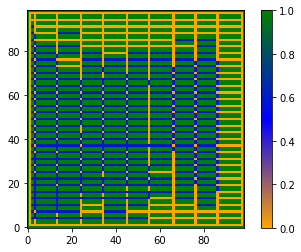

In [ ]:
counter=-1

key=[]
for z in Zone_total:
  counter=counter+1
  if z>=1:
     #val=zones_dictionary.get(a)
     key.append(next(((k,i) for (k,i) in zones_dictionary if zones_dictionary[(k,i)] == counter), None))
     #zones_dictionary.keys()[zones_dictionary.values(counter)]
     for i in zones_dictionary:
       #print(i)
       if zones_dictionary[i]==counter:
         key.append(i)


maze_2=maze1
print(key)
for k in key:
  maze_2[k]=0.6

from matplotlib import pyplot
import matplotlib as mpl

fig = pyplot.figure(2)

cmap2 = mpl.colors.LinearSegmentedColormap.from_list('my_colormap',
                                           ['orange','blue','green'],
                                           256)

img2 = pyplot.imshow(maze_2,interpolation='nearest',
                    cmap = cmap2,
                    origin='lower')

pyplot.colorbar(img2,cmap=cmap2)

fig.savefig("/content/gdrive/Shareddrives/Winter Simulation 2021/image_test_more_than_orequal1.png")

[(4, 3), (4, 3), (4, 4), (4, 4), (4, 5), (4, 6), (4, 7), (4, 8), (4, 9), (4, 10), (4, 11), (4, 12), (4, 13), (4, 13), (4, 14), (4, 14), (4, 15), (4, 16), (4, 17), (4, 18), (4, 19), (4, 20), (4, 21), (4, 22), (4, 23), (4, 24), (4, 24), (4, 25), (4, 25), (4, 26), (4, 27), (4, 28), (4, 29), (4, 30), (4, 31), (4, 32), (4, 33), (4, 34), (4, 34), (4, 35), (4, 35), (4, 36), (4, 37), (4, 38), (4, 39), (4, 40), (4, 41), (4, 42), (4, 43), (4, 44), (4, 45), (4, 45), (4, 46), (4, 46), (4, 47), (4, 48), (4, 49), (4, 50), (4, 51), (4, 52), (4, 53), (4, 54), (4, 55), (4, 55), (4, 56), (4, 56), (4, 57), (4, 58), (4, 59), (4, 60), (4, 61), (4, 62), (4, 63), (4, 64), (4, 65), (4, 66), (4, 66), (4, 67), (4, 67), (4, 68), (4, 69), (4, 70), (4, 71), (4, 72), (4, 73), (4, 74), (4, 75), (7, 3), (7, 3), (10, 3), (10, 3), (13, 2), (13, 2), (13, 3), (13, 3), (13, 4), (13, 4), (13, 5), (13, 6), (13, 7), (13, 8), (13, 9), (13, 10), (13, 11), (13, 12), (13, 13), (13, 13), (13, 14), (13, 14), (13, 15), (13, 16), (1

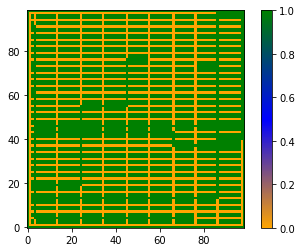

In [ ]:


from matplotlib import pyplot
import matplotlib as mpl

fig = pyplot.figure(2)

cmap2 = mpl.colors.LinearSegmentedColormap.from_list('my_colormap',
                                           ['orange','blue','green'],
                                           256)

img2 = pyplot.imshow(maze_2,interpolation='nearest',
                    cmap = cmap2,
                    origin='lower')

pyplot.colorbar(img2,cmap=cmap2)

fig.savefig("/content/gdrive/Shareddrives/Winter Simulation 2021/image_test_more_than_orequal1.png")

In [ ]:
#Start and end positions 
#More specifically - start , shelf, shelf,dock 
init=[]
final=[]
print(A1_n1_path)
for A1 in A1_n1_path:
      A1_n=[A1]
      #Zone_rack=[0]*(zone+1)
      for a in A1_n:
        #print(a)
        #print(a[0])
        init.append(a[0])
        final.append(a[-1])

[[(40, 51), (79, 8), (79, 9), (79, 10), (79, 11), (79, 12), (79, 13), (78, 13), (77, 13), (76, 13), (75, 13), (74, 13), (73, 13), (72, 13), (71, 13), (70, 13), (69, 13), (68, 13), (67, 13), (66, 13), (65, 13), (64, 13), (63, 13), (62, 13), (61, 13), (60, 13), (59, 13), (58, 13), (57, 13), (56, 13), (55, 13), (54, 13), (53, 13), (52, 13), (51, 13), (50, 13), (49, 13), (48, 13), (47, 13), (46, 13), (45, 13), (44, 13), (43, 13), (42, 13), (41, 13), (40, 13), (40, 14), (40, 15), (40, 16), (40, 17), (40, 18), (40, 19), (40, 20), (40, 21), (40, 22), (40, 23), (40, 24), (40, 25), (40, 26), (40, 27), (40, 28), (40, 29), (40, 30), (40, 31), (40, 32), (40, 33), (40, 34), (40, 35), (40, 36), (40, 37), (40, 38), (40, 39), (40, 40), (40, 41), (40, 42), (40, 43), (40, 44), (40, 45), (40, 46), (40, 47), (40, 48), (40, 49), (40, 50), (40, 51)], [(40, 50), (40, 49), (40, 48), (40, 47), (40, 46), (40, 45), (40, 44), (40, 43), (40, 42), (40, 41), (40, 40), (40, 39), (40, 38), (40, 37), (40, 36), (40, 35)

In [ ]:
print(init[0])

(40, 51)


In [ ]:
  from tqdm import tqdm
  from google.colab import files
  import random
  import pandas as pd
  import csv 
  import json
  #Start and end positions 
  #More specifically - start , shelf, shelf,dock 
  init=[]
  final=[]
  #print(A1_n1_path)
  for A1 in A1_n1_path:
      A1_n=[A1]
      #Zone_rack=[0]*(zone+1)
      for a in A1_n:
        #print(a)
        #print(a[0])
        init.append(a[0])
        final.append(a[-1])
  #def data_generator_for_nn(data_points):
  data_points=1
  ip_1_avoidall=[]
  ip_2_avoidall=[]
  op_1_avoidall=[]
  for N in range (0,data_points): 
    #print(n)
    #n = random. randint(10,15) #randomly generated number between 2 to 20 
    n=1
    A1_n1_avoidall=[]
    test_planner = PathPlanner(maze_2, True) 
    print(init)
    start=init[0]
    #print(type(start))
    start=list(start)
    temp=start
    start[1]=temp[0]
    start[0]=temp[1]
    end=final[0]
    temp1=end
    end=list(end)
    end[1]=temp1[0]
    end[0]=temp1[1]
    a1= test_planner.a_star(start,end) 
    print(type(a1))

    start=init[1]
    start=list(start)
    temp=start
    start[1]=temp[0]
    start[0]=temp[1]
    end=final[1]
    temp1=end
    end=list(end)
    end[1]=temp1[0]
    end[0]=temp1[1]
    a2= test_planner.a_star(start,end)  
    A1_n1_avoidall.append([a1])
    A1_n1_avoidall.append([a2])
    #print(A1_n1_avoid2)
    #print(len(A1_n1_avoid2))
    if ((len(A1_n1_avoidall)!=0 ) and (len(A1_n1_avoidall)!=0)):
            #writing number of vehicles begning their trip in each zone
            for A1 in A1_n1_avoidall:
              #print(A1)
              A1_n=[A1]
              Zone_start_trip=[0]*(zone+1)
              Zone_finish_trip=[0]*(zone+1)
              #Zone_rack=[0]*(zone+1)
              for a in A1_n1_avoidall:
                #print(a)
                print(a[0])
                temp_init=list(a[0][1])
                #print(temp_init)
                #temp=temp_init[0]
                #temp_init[0]=temp_init[1]
                #temp_init[1]=temp
                temp_init=tuple(temp_init)
                init=zones_dictionary.get(temp_init)
                #print(init)
                #print(data[init])
                Zone_start_trip[init]=Zone_start_trip[init]+1

              #writing number of vehicles ending their trip in each zone
              for A1 in A1_n1_avoidall:
                A1_n=[A1]
                #print(a[-1])
                temp_final=list(a[-1])
                #temp=temp_final[0]
                #temp_final[0]=temp_final[1]
                #temp_final[1]=temp
                #temp_final=tuple(temp_final)
                temp_final=tuple(temp_final)
                #print(temp_final)
                final=zones_dictionary.get(temp_final)
                #print(final)
                Zone_finish_trip[final]=Zone_finish_trip[final]+1
              #writing number of vehicles that go to a deck in a zone as intermediate point 

              #writing zone busy-ness
                  
              Z_n=Zone_business(A1_n1_avoidall)
              
              ip_1_avoidall.append(Zone_start_trip)
            
              ip_2_avoidall.append(Zone_finish_trip)
              
              #ip_3.append(Zone_rack)
            
              op_1_avoidall.append(Z_n)

if ((len(A1_n1_avoidall[0])!=0) and (len(A1_n1_avoidall[1])!=0)):       
          list_features_op_avoidall=[]
          list_features_op_avoidall.append(ip_1_avoidall)
          list_features_op_avoidall.append(ip_2_avoidall)
          #list_features_op.append(ip_3)
          list_features_op_avoidall.append(op_1_avoidall)
if ((len(A1_n1_avoidall[0])==0) or (len(A1_n1_avoidall[1])==0)):
    print("no path found")


[(79, 17), (79, 16)]
<class 'int'>
-1


TypeError: ignored

In [ ]:
arr=np.array(op_1_avoidall)
shape = arr.shape
zone_traversed_1= np.zeros(shape)
for x in range(0, shape[0]):
  for z in range(0, shape[1]):
        if arr[x][z] >= 1:
            zone_traversed_1[x][z] = 1
        else:
          zone_traversed_1[x][z] = 0



time_taken_A_Star_avoidall=sum(sum(zone_traversed_1))
print(time_taken_A_Star_avoidall)

 

TypeError: ignored

Trying to avoid regions with 2 or more vehicles

<class 'numpy.ndarray'>
1046
<class 'numpy.ndarray'>
1046
<class 'numpy.ndarray'>
1046
<class 'numpy.ndarray'>
1046
<class 'numpy.ndarray'>
1046
<class 'numpy.ndarray'>
1046
<class 'numpy.ndarray'>
1046
<class 'numpy.ndarray'>
1046
<class 'numpy.ndarray'>
1046
<class 'numpy.ndarray'>
1046
333
[(4, 4), (4, 4), (4, 5), (4, 6), (4, 7), (4, 8), (4, 9), (4, 10), (4, 11), (4, 12), (13, 3), (13, 3), (19, 3), (19, 3), (37, 86), (37, 86), (43, 3), (43, 3), (43, 24), (43, 24), (43, 56), (43, 56), (43, 57), (43, 58), (43, 59), (43, 60), (43, 61), (43, 62), (43, 63), (43, 64), (43, 65), (46, 3), (46, 3), (46, 24), (46, 24), (46, 86), (46, 86), (46, 87), (46, 87), (46, 88), (46, 89), (46, 90), (46, 91), (46, 92), (46, 93), (46, 94), (46, 95), (46, 96), (49, 3), (49, 3), (49, 86), (49, 86), (52, 3), (52, 3), (52, 86), (52, 86), (55, 3), (55, 3), (55, 86), (55, 86), (58, 3), (58, 3), (58, 86), (58, 86), (61, 3), (61, 3), (61, 86), (61, 86), (64, 3), (64, 3), (64, 86), (64, 86), (67, 3), (67, 3), (67,

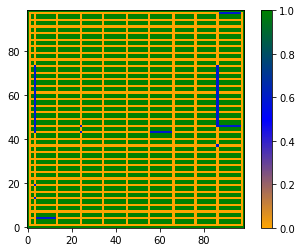

In [ ]:
import numpy as np
filein = "/content/gdrive/Shareddrives/Winter Simulation 2021/Layout_updated_2021 (1).csv"
data = np.loadtxt(open(filein, "rb"), delimiter=",")
#print(data)
maze1=np.array(data)
maze1 = np.where(maze1 == 100, 1, maze1)
maze1 = np.where(maze1 == -1, 1, maze1)
maze1 = np.where(maze1 == 200, 1, maze1)
maze1 = np.where(maze1 == 50, 0, maze1)


Zone_total=[0]*(zone+1)
trip=-1
for re in result_P:
      #print(re)
      print(type(re))
      print(len(re))
      c=-1
      trip=trip+1
      if (trip/2)==0:
        Zone_temp=[0]*(zone+1)
        for r in re:
            c=c+1
            #print(r)
            if r==1:
                Zone_total[c]=Zone_total[c]+1
                Zone_temp[c]=1
      if (trip/2)!=0:
        for r in re:
            c=c+1
            if r==1:
              if (Zone_temp[c]!=1):
                Zone_total[c]=Zone_total[c]+1

print(sum(Zone_total))

counter=-1

key=[]
for z in Zone_total:
  counter=counter+1
  if z>=2:
     #val=zones_dictionary.get(a)
     key.append(next(((k,i) for (k,i) in zones_dictionary if zones_dictionary[(k,i)] == counter), None))
     #zones_dictionary.keys()[zones_dictionary.values(counter)]
     for i in zones_dictionary:
       #print(i)
       if zones_dictionary[i]==counter:
         key.append(i)


maze_3=maze1
print(key)
for k in key:
  maze_3[k]=0.6

from matplotlib import pyplot
import matplotlib as mpl

fig = pyplot.figure(2)

cmap2 = mpl.colors.LinearSegmentedColormap.from_list('my_colormap',
                                           ['orange','blue','green'],
                                           256)

img2 = pyplot.imshow(maze_3,interpolation='nearest',
                    cmap = cmap2,
                    origin='lower')

pyplot.colorbar(img2,cmap=cmap2)

fig.savefig("/content/gdrive/Shareddrives/Winter Simulation 2021/image_test_more_than_orequal3_6_23_21.png")

In [ ]:
  from tqdm import tqdm
  from google.colab import files
  import random
  import pandas as pd
  import csv 
  import json
  #Start and end positions 
  #More specifically - start , shelf, shelf,dock 
  init=[]
  final=[]
  print(A1_n1_path)
  for A1 in A1_n1_path:
      A1_n=[A1]
      #Zone_rack=[0]*(zone+1)
      for a in A1_n:
        #print(a)
        #print(a[0])
        init.append(a[0])
        final.append(a[-1])
  #def data_generator_for_nn(data_points):
  data_points=1
  ip_1_avoid2=[]
  ip_2_avoid2=[]
  op_1_avoid2=[]
  for N in range (0,data_points): 
    #print(n)
    #n = random. randint(10,15) #randomly generated number between 2 to 20 
    n=1
    A1_n1_avoid2=[]
    test_planner = PathPlanner(maze_3, True) 
    print(init)
    start=init[0]
    #print(type(start))
    start=list(start)
    temp=start
    start[1]=temp[0]
    start[0]=temp[1]
    end=final[0]
    temp1=end
    end=list(end)
    end[1]=temp1[0]
    end[0]=temp1[1]
    a1= test_planner.a_star(start,end) 
    print(type(a1))

    start=init[1]
    start=list(start)
    temp=start
    start[1]=temp[0]
    start[0]=temp[1]
    end=final[1]
    temp1=end
    end=list(end)
    end[1]=temp1[0]
    end[0]=temp1[1]
    a2= test_planner.a_star(start,end)  
    A1_n1_avoid2.append(a1)
    A1_n1_avoid2.append(a2)
    #print(A1_n1_avoid2)
    #print(len(A1_n1_avoid2))
    if ((len(A1_n1_avoid2[0])!=0 ) and (len(A1_n1_avoid2[1])!=0)):
            #writing number of vehicles begning their trip in each zone
            for A1 in A1_n1_avoid2:
              print(A1)
              A1_n=[A1]
              Zone_start_trip=[0]*(zone+1)
              Zone_finish_trip=[0]*(zone+1)
              #Zone_rack=[0]*(zone+1)
              for a in A1_n1_avoid2:
                print(a)
                #print(a[0])
                temp_init=list(a[0])
                #temp=temp_init[0]
                #temp_init[0]=temp_init[1]
                #temp_init[1]=temp
                temp_init=tuple(temp_init)
                init=zones_dictionary.get(temp_init)
                #print(init)
                #print(data[init])
                Zone_start_trip[init]=Zone_start_trip[init]+1

              #writing number of vehicles ending their trip in each zone
              for A1 in A1_n1_avoid2:
                A1_n=[A1]
                #print(a[-1])
                temp_final=list(a[-1])
                #temp=temp_final[0]
                #temp_final[0]=temp_final[1]
                #temp_final[1]=temp
                #temp_final=tuple(temp_final)
                temp_final=tuple(temp_final)
                #print(temp_final)
                final=zones_dictionary.get(temp_final)
                #print(final)
                Zone_finish_trip[final]=Zone_finish_trip[final]+1
              #writing number of vehicles that go to a deck in a zone as intermediate point 

              #writing zone busy-ness
                  
              Z_n=Zone_business(A1_n1_avoid2)

              ip_1_avoid2.append(Zone_start_trip)
            
              ip_2_avoid2.append(Zone_finish_trip)
              
              #ip_3.append(Zone_rack)
            
              op_1_avoid2.append(Z_n)

if ((len(A1_n1_avoid2[0])!=0) and (len(A1_n1_avoid2[1])!=0)):       
          list_features_op_avoid2=[]
          list_features_op_avoid2.append(ip_1_avoid2)
          list_features_op_avoid2.append(ip_2_avoid2)
          #list_features_op.append(ip_3)
          list_features_op_avoid2.append(op_1_avoid2)
if ((len(A1_n1_avoid2[0])==0) or (len(A1_n1_avoid2[1])==0)):
    print("no path found")


[[(40, 51), (79, 8), (79, 9), (79, 10), (79, 11), (79, 12), (79, 13), (78, 13), (77, 13), (76, 13), (75, 13), (74, 13), (73, 13), (72, 13), (71, 13), (70, 13), (69, 13), (68, 13), (67, 13), (66, 13), (65, 13), (64, 13), (63, 13), (62, 13), (61, 13), (60, 13), (59, 13), (58, 13), (57, 13), (56, 13), (55, 13), (54, 13), (53, 13), (52, 13), (51, 13), (50, 13), (49, 13), (48, 13), (47, 13), (46, 13), (45, 13), (44, 13), (43, 13), (42, 13), (41, 13), (40, 13), (40, 14), (40, 15), (40, 16), (40, 17), (40, 18), (40, 19), (40, 20), (40, 21), (40, 22), (40, 23), (40, 24), (40, 25), (40, 26), (40, 27), (40, 28), (40, 29), (40, 30), (40, 31), (40, 32), (40, 33), (40, 34), (40, 35), (40, 36), (40, 37), (40, 38), (40, 39), (40, 40), (40, 41), (40, 42), (40, 43), (40, 44), (40, 45), (40, 46), (40, 47), (40, 48), (40, 49), (40, 50), (40, 51)], [(40, 50), (40, 49), (40, 48), (40, 47), (40, 46), (40, 45), (40, 44), (40, 43), (40, 42), (40, 41), (40, 40), (40, 39), (40, 38), (40, 37), (40, 36), (40, 35)

In [ ]:
arr=np.array(op_1_avoid2)
shape = arr.shape
zone_traversed_1= np.zeros(shape)
for x in range(0, shape[0]):
  for z in range(0, shape[1]):
        if arr[x][z] >= 1:
            zone_traversed_1[x][z] = 1
        else:
          zone_traversed_1[x][z] = 0



time_taken_A_Star_avoid2=sum(sum(zone_traversed_1))
#print(time_taken_A_Star_avoid2)


for zone_traversed_1 in op_1_avoid2:
      for i in range(0,len(zone_traversed[0])):
        if zone_traversed_counter[i]!=0:
            if Zone_total[i]==1:
              time_taken_A_Star_avoid2=time_taken_A_Star_avoid2+2


print(time_taken_naive_A_Star)   
print(time_taken_A_Star_avoid2)  

178.0
126.0


The same can be done for 3 

<class 'numpy.ndarray'>
1046
<class 'numpy.ndarray'>
1046
<class 'numpy.ndarray'>
1046
<class 'numpy.ndarray'>
1046
<class 'numpy.ndarray'>
1046
<class 'numpy.ndarray'>
1046
<class 'numpy.ndarray'>
1046
<class 'numpy.ndarray'>
1046
<class 'numpy.ndarray'>
1046
<class 'numpy.ndarray'>
1046
333
[(46, 3), (46, 3), (46, 86), (46, 86), (49, 3), (49, 3), (52, 3), (52, 3), (55, 3), (55, 3), (58, 3), (58, 3), (61, 3), (61, 3), (47, 3), (47, 3), (48, 3), (50, 3), (50, 3), (51, 3), (53, 3), (53, 3), (54, 3), (56, 3), (56, 3), (57, 3), (59, 3), (59, 3), (60, 3)]


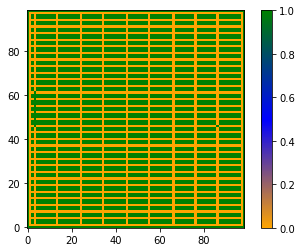

In [ ]:
import numpy as np
filein = "/content/gdrive/Shareddrives/Winter Simulation 2021/Layout_updated_2021 (1).csv"
data = np.loadtxt(open(filein, "rb"), delimiter=",")
#print(data)
maze1=np.array(data)
maze1 = np.where(maze1 == 100, 1, maze1)
maze1 = np.where(maze1 == -1, 1, maze1)
maze1 = np.where(maze1 == 200, 1, maze1)
maze1 = np.where(maze1 == 50, 0, maze1)


Zone_total=[0]*(zone+1)
trip=-1
for re in result_P:
      #print(re)
      print(type(re))
      print(len(re))
      c=-1
      trip=trip+1
      if (trip/2)==0:
        Zone_temp=[0]*(zone+1)
        for r in re:
            c=c+1
            #print(r)
            if r==1:
                Zone_total[c]=Zone_total[c]+1
                Zone_temp[c]=1
      if (trip/2)!=0:
        for r in re:
            c=c+1
            if r==1:
              if (Zone_temp[c]!=1):
                Zone_total[c]=Zone_total[c]+1

print(sum(Zone_total))

counter=-1

key=[]
for z in Zone_total:
  counter=counter+1
  if z>=3:
     #val=zones_dictionary.get(a)
     key.append(next(((k,i) for (k,i) in zones_dictionary if zones_dictionary[(k,i)] == counter), None))
     #zones_dictionary.keys()[zones_dictionary.values(counter)]
     for i in zones_dictionary:
       #print(i)
       if zones_dictionary[i]==counter:
         key.append(i)


maze_4=maze1
print(key)
for k in key:
  maze_4[k]=1

from matplotlib import pyplot
import matplotlib as mpl

fig = pyplot.figure(2)

cmap2 = mpl.colors.LinearSegmentedColormap.from_list('my_colormap',
                                           ['orange','blue','green'],
                                           256)

img2 = pyplot.imshow(maze_4,interpolation='nearest',
                    cmap = cmap2,
                    origin='lower')

pyplot.colorbar(img2,cmap=cmap2)

fig.savefig("/content/gdrive/Shareddrives/Winter Simulation 2021/image_test_more_than_orequal2.png")

In [ ]:
  from tqdm import tqdm
  from google.colab import files
  import random
  import pandas as pd
  import csv 
  import json
  #Start and end positions 
  #More specifically - start , shelf, shelf,dock 
  init=[]
  final=[]
  print(A1_n1_path)
  for A1 in A1_n1_path:
      A1_n=[A1]
      #Zone_rack=[0]*(zone+1)
      for a in A1_n:
        #print(a)
        #print(a[0])
        init.append(a[0])
        final.append(a[-1])
  #def data_generator_for_nn(data_points):
  data_points=1
  ip_1_avoid2=[]
  ip_2_avoid2=[]
  op_1_avoid2=[]
  for N in range (0,data_points): 
    #print(n)
    #n = random. randint(10,15) #randomly generated number between 2 to 20 
    n=1
    A1_n1_avoid2=[]
    test_planner = PathPlanner(maze_4, True) 
    print(init)
    start=init[0]
    #print(type(start))
    start=list(start)
    temp=start
    start[1]=temp[0]
    start[0]=temp[1]
    end=final[0]
    temp1=end
    end=list(end)
    end[1]=temp1[0]
    end[0]=temp1[1]
    a1= test_planner.a_star(start,end) 
    print(type(a1))

    start=init[1]
    start=list(start)
    temp=start
    start[1]=temp[0]
    start[0]=temp[1]
    end=final[1]
    temp1=end
    end=list(end)
    end[1]=temp1[0]
    end[0]=temp1[1]
    a2= test_planner.a_star(start,end)  
    A1_n1_avoid2.append(a1)
    A1_n1_avoid2.append(a2)
    #print(A1_n1_avoid2)
    #print(len(A1_n1_avoid2))
    if ((len(A1_n1_avoid2[0])!=0 ) and (len(A1_n1_avoid2[1])!=0)):
            #writing number of vehicles begning their trip in each zone
            for A1 in A1_n1_avoid2:
              print(A1)
              A1_n=[A1]
              Zone_start_trip=[0]*(zone+1)
              Zone_finish_trip=[0]*(zone+1)
              #Zone_rack=[0]*(zone+1)
              for a in A1_n1_avoid2:
                print(a)
                #print(a[0])
                temp_init=list(a[0])
                #temp=temp_init[0]
                #temp_init[0]=temp_init[1]
                #temp_init[1]=temp
                temp_init=tuple(temp_init)
                init=zones_dictionary.get(temp_init)
                #print(init)
                #print(data[init])
                Zone_start_trip[init]=Zone_start_trip[init]+1

              #writing number of vehicles ending their trip in each zone
              for A1 in A1_n1_avoid2:
                A1_n=[A1]
                #print(a[-1])
                temp_final=list(a[-1])
                #temp=temp_final[0]
                #temp_final[0]=temp_final[1]
                #temp_final[1]=temp
                #temp_final=tuple(temp_final)
                temp_final=tuple(temp_final)
                #print(temp_final)
                final=zones_dictionary.get(temp_final)
                #print(final)
                Zone_finish_trip[final]=Zone_finish_trip[final]+1
              #writing number of vehicles that go to a deck in a zone as intermediate point 

              #writing zone busy-ness
                  
              Z_n=Zone_business(A1_n1_avoid2)

              ip_1_avoid2.append(Zone_start_trip)
            
              ip_2_avoid2.append(Zone_finish_trip)
              
              #ip_3.append(Zone_rack)
            
              op_1_avoid2.append(Z_n)
              
if ((len(A1_n1_avoid2[0])!=0) and (len(A1_n1_avoid2[1])!=0)):       
          list_features_op_avoid2=[]
          list_features_op_avoid2.append(ip_1_avoid2)
          list_features_op_avoid2.append(ip_2_avoid2)
          #list_features_op.append(ip_3)
          list_features_op_avoid2.append(op_1_avoid2)
if ((len(A1_n1_avoid2[0])==0) or (len(A1_n1_avoid2[1])==0)):
    print("no path found")


[[(40, 51), (79, 8), (79, 9), (79, 10), (79, 11), (79, 12), (79, 13), (78, 13), (77, 13), (76, 13), (75, 13), (74, 13), (73, 13), (72, 13), (71, 13), (70, 13), (69, 13), (68, 13), (67, 13), (66, 13), (65, 13), (64, 13), (63, 13), (62, 13), (61, 13), (60, 13), (59, 13), (58, 13), (57, 13), (56, 13), (55, 13), (54, 13), (53, 13), (52, 13), (51, 13), (50, 13), (49, 13), (48, 13), (47, 13), (46, 13), (45, 13), (44, 13), (43, 13), (42, 13), (41, 13), (40, 13), (40, 14), (40, 15), (40, 16), (40, 17), (40, 18), (40, 19), (40, 20), (40, 21), (40, 22), (40, 23), (40, 24), (40, 25), (40, 26), (40, 27), (40, 28), (40, 29), (40, 30), (40, 31), (40, 32), (40, 33), (40, 34), (40, 35), (40, 36), (40, 37), (40, 38), (40, 39), (40, 40), (40, 41), (40, 42), (40, 43), (40, 44), (40, 45), (40, 46), (40, 47), (40, 48), (40, 49), (40, 50), (40, 51)], [(40, 50), (40, 49), (40, 48), (40, 47), (40, 46), (40, 45), (40, 44), (40, 43), (40, 42), (40, 41), (40, 40), (40, 39), (40, 38), (40, 37), (40, 36), (40, 35)

In [ ]:
arr=np.array(op_1_avoid2)
shape = arr.shape
zone_traversed_1= np.zeros(shape)
for x in range(0, shape[0]):
  for z in range(0, shape[1]):
        if arr[x][z] >= 1:
            zone_traversed_1[x][z] = 1
        else:
          zone_traversed_1[x][z] = 0



time_taken_A_Star_avoid2=sum(sum(zone_traversed_1))
#print(time_taken_A_Star_avoid2)


for zone_traversed_1 in op_1_avoid2:
      for i in range(0,len(zone_traversed[0])):
        if zone_traversed_counter[i]!=0:
            if Zone_total[i]==1:
              time_taken_A_Star_avoid2=time_taken_A_Star_avoid2+2
            if Zone_total[i]==2:
              time_taken_A_Star_avoid2=time_taken_A_Star_avoid2+3

print(time_taken_naive_A_Star)   
print(time_taken_A_Star_avoid2)  

178.0
186.0


And 5 if needed

<class 'numpy.ndarray'>
1046
<class 'numpy.ndarray'>
1046
<class 'numpy.ndarray'>
1046
<class 'numpy.ndarray'>
1046
<class 'numpy.ndarray'>
1046
<class 'numpy.ndarray'>
1046
<class 'numpy.ndarray'>
1046
<class 'numpy.ndarray'>
1046
<class 'numpy.ndarray'>
1046
<class 'numpy.ndarray'>
1046
333
[]


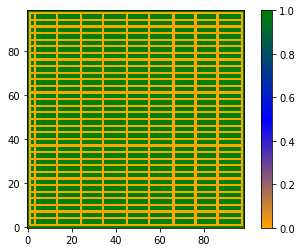

In [ ]:
import numpy as np
filein = "/content/gdrive/Shareddrives/Winter Simulation 2021/Layout_updated_2021 (1).csv"
data = np.loadtxt(open(filein, "rb"), delimiter=",")
#print(data)
maze1=np.array(data)
maze1 = np.where(maze1 == 100, 1, maze1)
maze1 = np.where(maze1 == -1, 1, maze1)
maze1 = np.where(maze1 == 200, 1, maze1)
maze1 = np.where(maze1 == 50, 0, maze1)


Zone_total=[0]*(zone+1)
trip=-1
for re in result_P:
      #print(re)
      print(type(re))
      print(len(re))
      c=-1
      trip=trip+1
      if (trip/2)==0:
        Zone_temp=[0]*(zone+1)
        for r in re:
            c=c+1
            #print(r)
            if r==1:
                Zone_total[c]=Zone_total[c]+1
                Zone_temp[c]=1
      if (trip/2)!=0:
        for r in re:
            c=c+1
            if r==1:
              if (Zone_temp[c]!=1):
                Zone_total[c]=Zone_total[c]+1

print(sum(Zone_total))

counter=-1

key=[]
for z in Zone_total:
  counter=counter+1
  if z>=4:
     #val=zones_dictionary.get(a)
     key.append(next(((k,i) for (k,i) in zones_dictionary if zones_dictionary[(k,i)] == counter), None))
     #zones_dictionary.keys()[zones_dictionary.values(counter)]
     for i in zones_dictionary:
       #print(i)
       if zones_dictionary[i]==counter:
         key.append(i)


maze_5=maze1
print(key)
for k in key:
  maze_5[k]=1

from matplotlib import pyplot
import matplotlib as mpl

fig = pyplot.figure(2)

cmap2 = mpl.colors.LinearSegmentedColormap.from_list('my_colormap',
                                           ['orange','blue','green'],
                                           256)

img2 = pyplot.imshow(maze_5,interpolation='nearest',
                    cmap = cmap2,
                    origin='lower')

pyplot.colorbar(img2,cmap=cmap2)

fig.savefig("/content/gdrive/Shareddrives/Winter Simulation 2021/image_test_more_than_orequal2.png")

In [ ]:
  from tqdm import tqdm
  from google.colab import files
  import random
  import pandas as pd
  import csv 
  import json
  #Start and end positions 
  #More specifically - start , shelf, shelf,dock 
  init=[]
  final=[]
  print(A1_n1_path)
  for A1 in A1_n1_path:
      A1_n=[A1]
      #Zone_rack=[0]*(zone+1)
      for a in A1_n:
        #print(a)
        #print(a[0])
        init.append(a[0])
        final.append(a[-1])
  #def data_generator_for_nn(data_points):
  data_points=1
  ip_1_avoid2=[]
  ip_2_avoid2=[]
  op_1_avoid2=[]
  for N in range (0,data_points): 
    #print(n)
    #n = random. randint(10,15) #randomly generated number between 2 to 20 
    n=1
    A1_n1_avoid2=[]
    test_planner = PathPlanner(maze_5, True) 
    print(init)
    start=init[0]
    #print(type(start))
    start=list(start)
    temp=start
    start[1]=temp[0]
    start[0]=temp[1]
    end=final[0]
    temp1=end
    end=list(end)
    end[1]=temp1[0]
    end[0]=temp1[1]
    a1= test_planner.a_star(start,end) 
    print(type(a1))

    start=init[1]
    start=list(start)
    temp=start
    start[1]=temp[0]
    start[0]=temp[1]
    end=final[1]
    temp1=end
    end=list(end)
    end[1]=temp1[0]
    end[0]=temp1[1]
    a2= test_planner.a_star(start,end)  
    A1_n1_avoid2.append(a1)
    A1_n1_avoid2.append(a2)
    #print(A1_n1_avoid2)
    #print(len(A1_n1_avoid2))
    if ((len(A1_n1_avoid2[0])!=0 ) and (len(A1_n1_avoid2[1])!=0)):
            #writing number of vehicles begning their trip in each zone
            for A1 in A1_n1_avoid2:
              print(A1)
              A1_n=[A1]
              Zone_start_trip=[0]*(zone+1)
              Zone_finish_trip=[0]*(zone+1)
              #Zone_rack=[0]*(zone+1)
              for a in A1_n1_avoid2:
                print(a)
                #print(a[0])
                temp_init=list(a[0])
                #temp=temp_init[0]
                #temp_init[0]=temp_init[1]
                #temp_init[1]=temp
                temp_init=tuple(temp_init)
                init=zones_dictionary.get(temp_init)
                #print(init)
                #print(data[init])
                Zone_start_trip[init]=Zone_start_trip[init]+1

              #writing number of vehicles ending their trip in each zone
              for A1 in A1_n1_avoid2:
                A1_n=[A1]
                #print(a[-1])
                temp_final=list(a[-1])
                #temp=temp_final[0]
                #temp_final[0]=temp_final[1]
                #temp_final[1]=temp
                #temp_final=tuple(temp_final)
                temp_final=tuple(temp_final)
                #print(temp_final)
                final=zones_dictionary.get(temp_final)
                #print(final)
                Zone_finish_trip[final]=Zone_finish_trip[final]+1
              #writing number of vehicles that go to a deck in a zone as intermediate point 

              #writing zone busy-ness
                  
              Z_n=Zone_business(A1_n1_avoid2)

              ip_1_avoid2.append(Zone_start_trip)
            
              ip_2_avoid2.append(Zone_finish_trip)
              
              #ip_3.append(Zone_rack)
            
              op_1_avoid2.append(Z_n)
              
if ((len(A1_n1_avoid2[0])!=0) and (len(A1_n1_avoid2[1])!=0)):       
          list_features_op_avoid2=[]
          list_features_op_avoid2.append(ip_1_avoid2)
          list_features_op_avoid2.append(ip_2_avoid2)
          #list_features_op.append(ip_3)
          list_features_op_avoid2.append(op_1_avoid2)
if ((len(A1_n1_avoid2[0])==0) or (len(A1_n1_avoid2[1])==0)):
    print("no path found")


[[(10, 91), (16, 84), (16, 85), (16, 86), (15, 86), (14, 86), (13, 86), (12, 86), (11, 86), (10, 86), (10, 87), (10, 88), (10, 89), (10, 90), (10, 91)], [(10, 90), (10, 89), (10, 88), (10, 87), (10, 86), (10, 85), (10, 84), (10, 83), (10, 82), (10, 81), (10, 80), (10, 79), (10, 78), (10, 77), (10, 76), (10, 75), (10, 74), (10, 73), (10, 72), (10, 71), (10, 70), (10, 69), (10, 68), (10, 67), (10, 66), (10, 65), (10, 64), (10, 63), (10, 62), (10, 61), (10, 60), (10, 59), (10, 58), (10, 57), (10, 56), (10, 55), (10, 54), (10, 53), (10, 52), (10, 51), (10, 50), (10, 49), (10, 48), (10, 47), (10, 46), (10, 45), (10, 44), (10, 43), (10, 42), (10, 41), (10, 40), (10, 39), (10, 38), (10, 37), (10, 36), (10, 35), (10, 34), (10, 33), (10, 32), (10, 31), (10, 30), (10, 29), (10, 28), (10, 27), (10, 26), (10, 25), (10, 24), (10, 23), (10, 22), (10, 21), (10, 20), (10, 19), (10, 18), (10, 17), (10, 16), (10, 15), (10, 14), (10, 13), (10, 12), (10, 11), (10, 10), (10, 9), (10, 8), (10, 7), (10, 6), 

In [ ]:
arr=np.array(op_1_avoid2)
shape = arr.shape
zone_traversed_1= np.zeros(shape)
for x in range(0, shape[0]):
  for z in range(0, shape[1]):
        if arr[x][z] >= 1:
            zone_traversed_1[x][z] = 1
        else:
          zone_traversed_1[x][z] = 0



time_taken_A_Star_avoid2=sum(sum(zone_traversed_1))
#print(time_taken_A_Star_avoid2)





print(time_taken_naive_A_Star)   
print(time_taken_A_Star_avoid2)  

65.20000000000005
118.0


Make intersection zones of their own
trip assumption remains same
5 vehicles - 1,2,3,or 4, 5


using the prediction model

In [ ]:
from numpy import sqrt
from pandas import read_csv
from sklearn.model_selection import train_test_split
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten
import tensorflow as tf
import pandas as pd
# load the dataset
import pickle
import numpy as np
import keras

pickle_off = open("/content/gdrive/Shareddrives/Winter Simulation 2021/data_for_pathplanning.pkl","rb")
emp = pickle.load(pickle_off)

In [ ]:
arr = np.asarray(emp)
X_T=np.array(emp[:2][:][:])
y_T=np.array(emp[2][:][:])
X_T=X_T.reshape(len(X_T[0]),len(X_T[0][0]),len(X_T))
y_T=y_T.reshape(len(y_T),len(y_T[0]))

In [ ]:
#print(emp)
print(len(emp[0][0]))
print(len(emp[0]))
print(len(emp))
print(type(emp))
arr = np.asarray(emp)
#print(arr)
print(arr.shape)
print(len(arr))
print(len(arr[0]))
print(len(arr[0][0]))
#(4, 1000, 352)
  

X_T=np.array(emp[:2][:][:])
y_T=np.array(emp[2][:][:])

print(X_T.shape)
print(y_T.shape)
#X = np.reshape(X, (353,3,1000)).T
X_T=X_T.reshape(len(X_T[0]),len(X_T[0][0]),len(X_T))
y_T=y_T.reshape(len(y_T),len(y_T[0]))
#y = np.reshape(y, (354,1,1000)).T

print(X_T.shape)
print(y_T.shape)
print(len(X_T[0][0]))
print(len(X_T[0]))
print(len(X_T))
#print(X)
# split into train and test datasets
#X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33)
#print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

# determine the number of input features
#n_features = X_train.shape[1]
#n_features = X_train.shape
#n_features_l=n_features[0]
#n_features_b=n_features[1]
#y_len=y_train.shape

arr=y_T
shape = arr.shape
result_T = np.zeros(shape)
for x in range(0, shape[0]):
  for z in range(0, shape[1]):
        if arr[x][z] >= 1:
            result_T[x][z] = 1
        else:
          result_T[x][z] = 0
print(result_T)
print(y_T)

1090
10
3
<class 'list'>
(3, 10, 1090)
3
10
1090
(2, 10, 1090)
(10, 1090)
(10, 1090, 2)
(10, 1090)
2
1090
10
[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]
[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


In [ ]:
X_T=X_T.reshape(len(X_T),len(X_T[0])*len(X_T[0][0]))
print(X_T.shape)

(10, 2180)


In [ ]:
y_pred_T=model.predict(X_T)

<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
0
[]


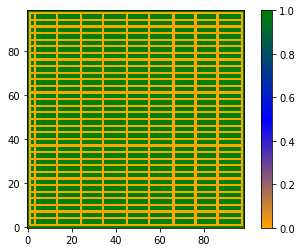

In [ ]:
import numpy as np
filein = "/content/gdrive/Shareddrives/Winter Simulation 2021/Layout_updated_2021 (1).csv"
data = np.loadtxt(open(filein, "rb"), delimiter=",")
#print(data)
maze1=np.array(data)
maze1 = np.where(maze1 == 100, 1, maze1)
maze1 = np.where(maze1 == -1, 1, maze1)
maze1 = np.where(maze1 == 200, 1, maze1)
maze1 = np.where(maze1 == 50, 0, maze1)


Zone_total_Pred=[0]*(zone+1)
trip=-1
for re in y_pred_T:
      #print(re)
      print(type(re))
      print(len(re))
      c=-1
      trip=trip+1
      if (trip/2)==0:
        Zone_temp=[0]*(zone+1)
        for r in re:
            c=c+1
            #print(r)
            if r==1:
                Zone_total_Pred[c]=Zone_total_Pred[c]+1
                Zone_temp[c]=1
      if (trip/2)!=0:
        for r in re:
            c=c+1
            if r==1:
              if (Zone_temp[c]!=1):
                Zone_total_Pred[c]=Zone_total_Pred[c]+1

print(sum(Zone_total_Pred))

counter=-1

key=[]
for z in Zone_total_Pred:
  counter=counter+1
  if z>=1:
     #val=zones_dictionary.get(a)
     key.append(next(((k,i) for (k,i) in zones_dictionary if zones_dictionary[(k,i)] == counter), None))
     #zones_dictionary.keys()[zones_dictionary.values(counter)]
     for i in zones_dictionary:
       #print(i)
       if zones_dictionary[i]==counter:
         key.append(i)


maze_6=maze1
print(key)
for k in key:
  maze_2[k]=0.6

from matplotlib import pyplot
import matplotlib as mpl

fig = pyplot.figure(2)

cmap2 = mpl.colors.LinearSegmentedColormap.from_list('my_colormap',
                                           ['orange','blue','green'],
                                           256)

img2 = pyplot.imshow(maze_6,interpolation='nearest',
                    cmap = cmap2,
                    origin='lower')

pyplot.colorbar(img2,cmap=cmap2)

fig.savefig("/content/gdrive/Shareddrives/Winter Simulation 2021/image_test_more_than_orequal3.png")

Risk of collission etc
Arent measured by the simulation method
They can be the advantage


Abstract-
Introduction - 
Motivation 
Innovation 
Explain the problem

Introduction culminates to the problem
Literature review section- can be short
More papers , less details
10 or so very recent related references, takes up 1/2 or 3/4th of the page
Methodology section 
System description 
Technical methodology 
implementation - setting up and determining models
Patricks paper - reference
Images-
ground truth 
predicted path 
A* path 
Alternate path 
Experimental section 
Conclusion and future work 